In [2]:
print("Fake News Trust Analyzer")
print("Notebook is working!")

Fake News Trust Analyzer
Notebook is working!


In [3]:
import pandas as pd
import sklearn
import spacy

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("spaCy:", spacy.__version__)

pandas: 3.0.5
scikit-learn: 1.9.0
spaCy: 3.8.16


In [4]:
import pandas as pd

fake_df = pd.read_csv("../data/Fake.csv")
true_df = pd.read_csv("../data/True.csv")

print("Fake news articles:", len(fake_df))
print("Real news articles:", len(true_df))

Fake news articles: 23481
Real news articles: 21417


In [5]:
print("Fake dataset columns:")
print(fake_df.columns.tolist())

print("\nReal dataset columns:")
print(true_df.columns.tolist())

Fake dataset columns:
['title', 'text', 'subject', 'date']

Real dataset columns:
['title', 'text', 'subject', 'date']


In [6]:
print("TITLE:")
print(fake_df.iloc[0]["title"])

print("\nARTICLE TEXT:")
print(fake_df.iloc[0]["text"][:1000])

TITLE:
 Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing

ARTICLE TEXT:
Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year 

In [7]:
print("Missing values in Fake dataset:")
print(fake_df.isnull().sum())

print("\nMissing values in Real dataset:")
print(true_df.isnull().sum())

Missing values in Fake dataset:
title      0
text       0
subject    0
date       0
dtype: int64

Missing values in Real dataset:
title      0
text       0
subject    0
date       0
dtype: int64


In [8]:
print("Duplicate rows in Fake dataset:", fake_df.duplicated().sum())
print("Duplicate rows in Real dataset:", true_df.duplicated().sum())

Duplicate rows in Fake dataset: 3
Duplicate rows in Real dataset: 206


In [9]:
fake_df["label"] = 0
true_df["label"] = 1

In [10]:
df = pd.concat([fake_df, true_df], ignore_index=True)

In [11]:
print("Total articles:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nLabel distribution:")
print(df["label"].value_counts())

Total articles: 44898

Columns:
['title', 'text', 'subject', 'date', 'label']

Label distribution:
label
0    23481
1    21417
Name: count, dtype: int64


In [12]:
df = df.drop_duplicates().reset_index(drop=True)

In [13]:
print("Articles after removing duplicates:", len(df))
print("\nLabel distribution after removing duplicates:")
print(df["label"].value_counts())

Articles after removing duplicates: 44689

Label distribution after removing duplicates:
label
0    23478
1    21211
Name: count, dtype: int64


In [14]:
df.to_csv("../data/news_dataset.csv", index=False)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


In [15]:
sample_text = df.iloc[0]["text"]

print("RAW ARTICLE TEXT:")
print(sample_text[:2000])

RAW ARTICLE TEXT:
Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year s greeting like this despicable, petty, infantile gibberish? Only Trump! His lack of

In [16]:
print("Text type:", type(sample_text))
print("Number of characters:", len(sample_text))

Text type: <class 'str'>
Number of characters: 2893


In [17]:
sample_title = df.iloc[0]["title"]

print("TITLE:")
print(sample_title)

print("\nTitle length:", len(sample_title))

TITLE:
 Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing

Title length: 79


In [18]:
sample_text = df.iloc[0]["text"]

print("RAW ARTICLE TEXT:")
print(sample_text[:2000])

print("\nText type:", type(sample_text))
print("Number of characters:", len(sample_text))

RAW ARTICLE TEXT:
Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year s greeting like this despicable, petty, infantile gibberish? Only Trump! His lack of

In [19]:
sample_title = df.iloc[0]["title"]

print("TITLE:")
print(sample_title)

print("\nTitle length:", len(sample_title))

TITLE:
 Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing

Title length: 79


In [20]:
import re
from bs4 import BeautifulSoup

def clean_text(text):
    # Make sure the input is a string
    text = str(text)

    # Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text(" ")

    # Replace multiple spaces/newlines with one space
    text = re.sub(r"\s+", " ", text)

    # Remove spaces from the beginning and end
    text = text.strip()

    return text

In [21]:
sample_clean = clean_text(sample_text)

print("BEFORE:")
print(sample_text[:500])

print("\nAFTER:")
print(sample_clean[:500])

BEFORE:
Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a gr

AFTER:
Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and the very dishonest fake news media. The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year, President Angry Pants tweeted. 2018

In [22]:
df["clean_text"] = df["text"].apply(clean_text)

C:\Users\Admin\AppData\Local\Temp\ipykernel_22568\2318392796.py:9: MarkupResemblesLocatorWarning: The input passed in on this line looks more like a URL than HTML or XML.

If you meant to use Beautiful Soup to parse the web page found at a certain URL, then something has gone wrong. You should use an Python package like 'requests' to fetch the content behind the URL. Once you have the content as a string, you can feed that string into Beautiful Soup.

However, if you want to parse some data that happens to look like a URL, then nothing has gone wrong: you are using Beautiful Soup correctly, and this warning is spurious and can be filtered. To make this warning go away, run this code before calling the BeautifulSoup constructor:

    from bs4 import MarkupResemblesLocatorWarning
    import warnings

    warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
    
  text = BeautifulSoup(text, "html.parser").get_text(" ")


In [23]:
print(df[["text", "clean_text"]].head(3))

                                                text  \
0  Donald Trump just couldn t wish all Americans ...   
1  House Intelligence Committee Chairman Devin Nu...   
2  On Friday, it was revealed that former Milwauk...   

                                          clean_text  
0  Donald Trump just couldn t wish all Americans ...  
1  House Intelligence Committee Chairman Devin Nu...  
2  On Friday, it was revealed that former Milwauk...  


In [24]:
print("Original text columns:", df.columns.tolist())

Original text columns: ['title', 'text', 'subject', 'date', 'label', 'clean_text']


In [25]:
df.to_csv("../data/news_dataset_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [26]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

Rows: 44689
Columns: 6


In [27]:
print(df["label"].value_counts())

label
0    23478
1    21211
Name: count, dtype: int64


In [28]:
df["text_length"] = df["clean_text"].str.len()

In [29]:
print(df["text_length"].describe())

count    44689.000000
mean      2455.744993
std       2159.433283
min          0.000000
25%       1227.000000
50%       2175.000000
75%       3088.000000
max      51493.000000
Name: text_length, dtype: float64


In [30]:
print(df.groupby("label")["text_length"].mean())

label
0    2534.058651
1    2369.061289
Name: text_length, dtype: float64


In [31]:
empty_articles = (df["clean_text"].str.strip() == "").sum()

print("Empty articles:", empty_articles)

Empty articles: 631


In [32]:
empty_rows = df[df["clean_text"].str.strip() == ""]

print(empty_rows[["title", "text", "label"]])

                                                   title text  label
10922  TAKE OUR POLL: Who Do You Think President Trum...           0
11040  Joe Scarborough BERATES Mika Brzezinski Over “...           0
11189  WATCH TUCKER CARLSON Scorch Sanctuary City May...           0
11224  MAYOR OF SANCTUARY CITY: Trump Trying To Make ...           0
11235  SHOCKER: Public School Turns Computer Lab Into...           0
...                                                  ...  ...    ...
21823  FULL VIDEO: THE BLOCKBUSTER INVESTIGATION INTO...           0
21824  (VIDEO) HILLARY CLINTON: RELIGIOUS BELIEFS MUS...           0
21854  (VIDEO)ICE PROTECTING OBAMA: WON’T RELEASE NAM...           0
21870  (VIDEO) HYSTERICAL SNL TAKE ON HILLARY’S ANNOU...           0
32402                     Graphic: Supreme Court roundup           1

[631 rows x 3 columns]


In [33]:
short_articles = df[df["text_length"] < 100]

print("Articles with fewer than 100 characters:", len(short_articles))

Articles with fewer than 100 characters: 1048


In [34]:
print(short_articles[["title", "text", "label", "text_length"]].head(10))

                                                   title  \
10922  TAKE OUR POLL: Who Do You Think President Trum...   
11040  Joe Scarborough BERATES Mika Brzezinski Over “...   
11116  MY FAVORITE EXCUSES…Featuring Hillary Rotten C...   
11189  WATCH TUCKER CARLSON Scorch Sanctuary City May...   
11224  MAYOR OF SANCTUARY CITY: Trump Trying To Make ...   
11232  JUDGE JEANINE’S OPENING STATEMENT: “Our Presid...   
11235  SHOCKER: Public School Turns Computer Lab Into...   
11240  BOOM! SEAN SPICER: “Trump Sold Hotels In Russi...   
11246  MICHAEL FLYNN’S LAWYER Releases Statement Scor...   
11248  ROB SCHNEIDER Nails The Russia Conspiracy Theo...   

                                                    text  label  text_length  
10922                                                         0            0  
11040                                                         0            0  
11116                                             Enjoy:      0            6  
11189                  

In [35]:
print(
    df[df["text_length"] < 100]["label"].value_counts()
)

label
0    1047
1       1
Name: count, dtype: int64


In [36]:
for threshold in [100, 250, 500, 1000]:
    count = (df["text_length"] < threshold).sum()
    print(f"Articles shorter than {threshold} characters: {count}")

Articles shorter than 100 characters: 1048
Articles shorter than 250 characters: 1901
Articles shorter than 500 characters: 4526
Articles shorter than 1000 characters: 9452


In [37]:
ml_df = df[df["clean_text"].str.strip() != ""].copy()

print("Original articles:", len(df))
print("Articles for ML:", len(ml_df))
print("Removed empty articles:", len(df) - len(ml_df))

Original articles: 44689
Articles for ML: 44058
Removed empty articles: 631


In [38]:
print("\nLabel distribution:")
print(ml_df["label"].value_counts())


Label distribution:
label
0    22848
1    21210
Name: count, dtype: int64


In [39]:
ml_df["model_text"] = (
    ml_df["title"].fillna("") + " " + ml_df["clean_text"].fillna("")
)

print(ml_df[["title", "model_text", "label"]].head(2))

                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   

                                          model_text  label  
0   Donald Trump Sends Out Embarrassing New Year’...      0  
1   Drunk Bragging Trump Staffer Started Russian ...      0  


In [40]:
X = ml_df["model_text"]
y = ml_df["label"]

print("X:", X.shape)
print("y:", y.shape)

X: (44058,)
y: (44058,)


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [42]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training samples: 35246
Testing samples: 8812

Training labels:
label
0    18278
1    16968
Name: count, dtype: int64

Testing labels:
label
0    4570
1    4242
Name: count, dtype: int64


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words="english"
)

In [44]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [45]:
X_test_tfidf = tfidf.transform(X_test)

In [46]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35246, 50000)
Testing TF-IDF shape: (8812, 50000)


In [47]:
feature_names = tfidf.get_feature_names_out()

print("Number of features:", len(feature_names))
print("\nFirst 30 features:")
print(feature_names[:30])

Number of features: 50000

First 30 features:
['00' '00 mark' '00 pm' '000' '000 000' '000 10' '000 according'
 '000 acres' '000 additional' '000 american' '000 americans' '000 barrels'
 '000 bond' '000 cases' '000 children' '000 civilians' '000 clinton'
 '000 donation' '000 donations' '000 emails' '000 employees' '000 euros'
 '000 federal' '000 fighters' '000 fine' '000 followers' '000 homes'
 '000 illegal' '000 immigrants' '000 jobs']


In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [50]:
model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [51]:
y_pred = model.predict(X_test_tfidf)

print("Predictions generated:", len(y_pred))

Predictions generated: 8812


In [52]:
print("Actual:", y_test.iloc[:10].tolist())
print("Predicted:", y_pred[:10].tolist())

Actual: [1, 1, 0, 0, 0, 1, 0, 0, 1, 1]
Predicted: [1, 1, 0, 0, 0, 1, 0, 0, 1, 1]


In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [54]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.9894
Precision: 0.9857
Recall   : 0.9925
F1-score : 0.9891


In [55]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake", "Real"]
))


Classification Report:
              precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      4570
        Real       0.99      0.99      0.99      4242

    accuracy                           0.99      8812
   macro avg       0.99      0.99      0.99      8812
weighted avg       0.99      0.99      0.99      8812



In [56]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[4509   61]
 [  32 4210]]


## Baseline Model Results

Model: TF-IDF + Logistic Regression

Test samples: 8,812

Accuracy: 98.94%
Precision: 98.57%
Recall: 99.25%
F1-score: 98.91%

Confusion Matrix:
[[4509, 61],
 [32, 4210]]

In [57]:
print("SUBJECT DISTRIBUTION BY LABEL")
print(pd.crosstab(df["subject"], df["label"]))

print("\n\nDATE RANGE BY LABEL")
print(df.groupby("label")["date"].agg(["min", "max"]))

print("\n\nNUMBER OF UNIQUE DATES")
print(df.groupby("label")["date"].nunique())

SUBJECT DISTRIBUTION BY LABEL
label               0      1
subject                     
Government News  1570      0
Middle-east       778      0
News             9050      0
US_News           783      0
left-news        4459      0
politics         6838      0
politicsNews        0  11220
worldnews           0   9991


DATE RANGE BY LABEL
                  min                                                max
label                                                                   
0           14-Feb-18  https://fedup.wpengine.com/wp-content/uploads/...
1      April 1, 2016                                  September 9, 2017 


NUMBER OF UNIQUE DATES
label
0    1681
1     716
Name: date, dtype: int64


In [58]:
# Compare title + body with body only

X_body = ml_df["clean_text"]

X_body_train, X_body_test, y_body_train, y_body_test = train_test_split(
    X_body,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

tfidf_body = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words="english"
)

X_body_train_tfidf = tfidf_body.fit_transform(X_body_train)
X_body_test_tfidf = tfidf_body.transform(X_body_test)

body_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

body_model.fit(X_body_train_tfidf, y_body_train)

y_body_pred = body_model.predict(X_body_test_tfidf)

print("BODY-ONLY RESULTS")
print("------------------")
print("Accuracy:", accuracy_score(y_body_test, y_body_pred))
print("Precision:", precision_score(y_body_test, y_body_pred))
print("Recall:", recall_score(y_body_test, y_body_pred))
print("F1-score:", f1_score(y_body_test, y_body_pred))

BODY-ONLY RESULTS
------------------
Accuracy: 0.9885383567862006
Precision: 0.985008198641368
Recall: 0.9912776991984913
F1-score: 0.9881330043473152


In [59]:
# Check for duplicate article bodies

duplicate_texts = ml_df["clean_text"].duplicated().sum()

print("Duplicate article bodies:", duplicate_texts)
print("Total ML articles:", len(ml_df))

Duplicate article bodies: 5420
Total ML articles: 44058


In [60]:
# Remove duplicate article bodies for a leakage-safe experiment

ml_df_unique = ml_df.drop_duplicates(
    subset=["clean_text"]
).reset_index(drop=True)

print("Original ML articles:", len(ml_df))
print("After removing duplicate bodies:", len(ml_df_unique))
print("Articles removed:", len(ml_df) - len(ml_df_unique))

print("\nLabel distribution:")
print(ml_df_unique["label"].value_counts())

Original ML articles: 44058
After removing duplicate bodies: 38638
Articles removed: 5420

Label distribution:
label
1    21189
0    17449
Name: count, dtype: int64


In [61]:
# Create a leakage-safe train/test split

X_unique = (
    ml_df_unique["title"].fillna("")
    + " "
    + ml_df_unique["clean_text"].fillna("")
)

y_unique = ml_df_unique["label"]

X_unique_train, X_unique_test, y_unique_train, y_unique_test = train_test_split(
    X_unique,
    y_unique,
    test_size=0.20,
    random_state=42,
    stratify=y_unique
)

print("Training articles:", len(X_unique_train))
print("Testing articles:", len(X_unique_test))

print("\nTraining label distribution:")
print(y_unique_train.value_counts())

print("\nTesting label distribution:")
print(y_unique_test.value_counts())

Training articles: 30910
Testing articles: 7728

Training label distribution:
label
1    16951
0    13959
Name: count, dtype: int64

Testing label distribution:
label
1    4238
0    3490
Name: count, dtype: int64


In [62]:
# TF-IDF on the leakage-safe dataset

tfidf_unique = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words="english"
)

X_unique_train_tfidf = tfidf_unique.fit_transform(X_unique_train)
X_unique_test_tfidf = tfidf_unique.transform(X_unique_test)

print("Training TF-IDF shape:", X_unique_train_tfidf.shape)
print("Testing TF-IDF shape:", X_unique_test_tfidf.shape)

Training TF-IDF shape: (30910, 50000)
Testing TF-IDF shape: (7728, 50000)


In [63]:
# Train Logistic Regression on the duplicate-free dataset

unique_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

unique_model.fit(X_unique_train_tfidf, y_unique_train)

y_unique_pred = unique_model.predict(X_unique_test_tfidf)

print("LEAKAGE-SAFE MODEL RESULTS")
print("--------------------------")
print("Accuracy:", accuracy_score(y_unique_test, y_unique_pred))
print("Precision:", precision_score(y_unique_test, y_unique_pred))
print("Recall:", recall_score(y_unique_test, y_unique_pred))
print("F1-score:", f1_score(y_unique_test, y_unique_pred))

LEAKAGE-SAFE MODEL RESULTS
--------------------------
Accuracy: 0.9833074534161491
Precision: 0.9765715611227094
Recall: 0.9933931099575272
F1-score: 0.984910515849807


Confusion Matrix:
[[3389  101]
 [  28 4210]]


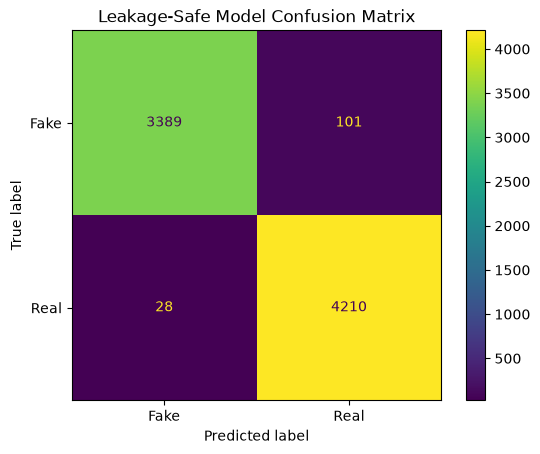

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_unique = confusion_matrix(y_unique_test, y_unique_pred)

print("Confusion Matrix:")
print(cm_unique)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_unique,
    display_labels=["Fake", "Real"]
)

disp.plot()
plt.title("Leakage-Safe Model Confusion Matrix")
plt.show()

### Leakage-Safe Model Results

After removing duplicate article bodies, the Logistic Regression model was evaluated on a separate test set.

- Accuracy: **98.33%**
- Precision: **97.66%**
- Recall: **99.34%**
- F1-score: **98.49%**

Confusion Matrix:

| | Predicted Fake | Predicted Real |
|---|---:|---:|
| Actual Fake | 3,389 | 101 |
| Actual Real | 28 | 4,210 |

The leakage-safe evaluation produced slightly lower performance than the original model (98.94% accuracy), indicating that duplicate articles contributed to the initial performance. However, the model continued to achieve strong performance after duplicate removal.

In [65]:
from sklearn.svm import LinearSVC

# Train Linear SVM
svm_model = LinearSVC(
    random_state=42
)

svm_model.fit(X_unique_train_tfidf, y_unique_train)

# Predictions
y_svm_pred = svm_model.predict(X_unique_test_tfidf)

print("LINEAR SVM RESULTS")
print("------------------")
print("Accuracy:", accuracy_score(y_unique_test, y_svm_pred))
print("Precision:", precision_score(y_unique_test, y_svm_pred))
print("Recall:", recall_score(y_unique_test, y_svm_pred))
print("F1-score:", f1_score(y_unique_test, y_svm_pred))

LINEAR SVM RESULTS
------------------
Accuracy: 0.9922360248447205
Precision: 0.9892271662763467
Recall: 0.9966965549787635
F1-score: 0.9929478138222849


In [66]:
from sklearn.naive_bayes import MultinomialNB

# Train Naive Bayes
nb_model = MultinomialNB()

nb_model.fit(X_unique_train_tfidf, y_unique_train)

# Predictions
y_nb_pred = nb_model.predict(X_unique_test_tfidf)

print("NAIVE BAYES RESULTS")
print("-------------------")
print("Accuracy:", accuracy_score(y_unique_test, y_nb_pred))
print("Precision:", precision_score(y_unique_test, y_nb_pred))
print("Recall:", recall_score(y_unique_test, y_nb_pred))
print("F1-score:", f1_score(y_unique_test, y_nb_pred))

NAIVE BAYES RESULTS
-------------------
Accuracy: 0.9491459627329193
Precision: 0.9528857479387515
Recall: 0.9544596507786692
F1-score: 0.9536720499823176


### Model Comparison

Three machine-learning models were evaluated using the duplicate-free dataset and the same TF-IDF features.

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 98.33% | 97.66% | 99.34% | 98.49% |
| Linear SVM | **99.22%** | **98.92%** | **99.67%** | **99.29%** |
| Naive Bayes | 94.91% | 95.29% | 95.45% | 95.37% |

Linear SVM achieved the best overall performance and was selected as the primary classifier for further development.

In [67]:
import joblib
import os

# Make sure the models folder exists
os.makedirs("../models", exist_ok=True)

# Save the trained model and TF-IDF vectorizer
joblib.dump(svm_model, "../models/linear_svm_model.pkl")
joblib.dump(tfidf_unique, "../models/tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!


In [68]:
import joblib

# Load the saved model and vectorizer
loaded_model = joblib.load("../models/linear_svm_model.pkl")
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

print("Loaded model:", type(loaded_model).__name__)
print("Loaded vectorizer:", type(loaded_tfidf).__name__)

# Test on one article from the test set
sample_text = X_unique_test.iloc[0]

sample_features = loaded_tfidf.transform([sample_text])
sample_prediction = loaded_model.predict(sample_features)[0]

print("\nSample prediction:", sample_prediction)
print("Actual label:", y_unique_test.iloc[0])

Loaded model: LinearSVC
Loaded vectorizer: TfidfVectorizer

Sample prediction: 1
Actual label: 1


In [69]:
# Calculate basic text-length features

ml_df["char_count"] = ml_df["clean_text"].str.len()

ml_df["word_count"] = ml_df["clean_text"].str.split().str.len()

print("Character count:")
print(ml_df["char_count"].describe())

print("\nWord count:")
print(ml_df["word_count"].describe())

Character count:
count    44058.000000
mean      2490.916247
std       2154.606411
min          5.000000
25%       1285.000000
50%       2196.000000
75%       3109.750000
max      51493.000000
Name: char_count, dtype: float64

Word count:
count    44058.000000
mean       410.752644
std        350.688085
min          1.000000
25%        212.000000
50%        365.000000
75%        515.000000
max       8135.000000
Name: word_count, dtype: float64


In [70]:
# Calculate sentence and punctuation features

ml_df["sentence_count"] = ml_df["clean_text"].str.count(r"[.!?]")

ml_df["exclamation_count"] = ml_df["clean_text"].str.count("!")

ml_df["question_count"] = ml_df["clean_text"].str.count(r"\?")

ml_df["uppercase_count"] = ml_df["clean_text"].str.count(r"\b[A-Z]{2,}\b")

print("Average sentence count:", ml_df["sentence_count"].mean())
print("Average exclamation marks:", ml_df["exclamation_count"].mean())
print("Average question marks:", ml_df["question_count"].mean())
print("Average uppercase words:", ml_df["uppercase_count"].mean())

Average sentence count: 22.302850787598167
Average exclamation marks: 0.410685914022425
Average question marks: 0.688546915429661
Average uppercase words: 5.03268418902356


In [71]:
# Compare linguistic features between Fake and Real articles

feature_comparison = ml_df.groupby("label")[
    [
        "char_count",
        "word_count",
        "sentence_count",
        "exclamation_count",
        "question_count",
        "uppercase_count"
    ]
].mean()

feature_comparison.index = ["Fake", "Real"]

print(feature_comparison)

       char_count  word_count  sentence_count  exclamation_count  \
Fake  2603.931591  434.867516       23.417104           0.734287   
Real  2369.172984  384.775436       21.102546           0.062093   

      question_count  uppercase_count  
Fake        1.234594         6.361213  
Real        0.100330         3.601556  


In [72]:
def extract_linguistic_features(text):
    text = str(text)

    features = {
        "char_count": len(text),
        "word_count": len(text.split()),
        "sentence_count": len(re.findall(r"[.!?]", text)),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),
        "uppercase_count": len(re.findall(r"\b[A-Z]{2,}\b", text))
    }

    return features


# Test the function
sample_features = extract_linguistic_features(
    "BREAKING NEWS! This is a sample article. Is this reliable?"
)

print(sample_features)

{'char_count': 58, 'word_count': 10, 'sentence_count': 3, 'exclamation_count': 1, 'question_count': 1, 'uppercase_count': 2}


In [74]:
# Improved clickbait detection

clickbait_phrases = [
    "you won't believe what",
    "you won't believe",
    "shocking truth",
    "what happens next",
    "this is what happened",
    "must see",
    "breaking",
    "urgent",
    "unbelievable",
    "mind blowing",
    "secret",
    "the truth about",
    "revealed",
    "shocking"
]


def detect_clickbait(title):
    title = str(title).lower()

    matched_phrases = []

    for phrase in clickbait_phrases:
        if phrase in title:
            # Avoid counting shorter phrases contained
            # inside a longer matched phrase
            if not any(
                phrase != other and phrase in other
                for other in matched_phrases
            ):
                matched_phrases.append(phrase)

    exclamation_count = title.count("!")
    question_count = title.count("?")

    uppercase_words = re.findall(r"\b[A-Z]{2,}\b", str(title))

    score = 0

    score += len(matched_phrases) * 2

    if exclamation_count >= 2:
        score += 1

    if question_count >= 2:
        score += 1

    if len(uppercase_words) >= 2:
        score += 1

    clickbait_score = min(score * 20, 100)

    return {
        "clickbait_score": clickbait_score,
        "matched_phrases": matched_phrases
    }


# Test
test_title = "SHOCKING! You won't believe what happens next!"

print(detect_clickbait(test_title))

{'clickbait_score': 100, 'matched_phrases': ["you won't believe what", 'what happens next', 'shocking']}


In [75]:
test_titles = [
    "Government announces new education policy",
    "BREAKING! SHOCKING news you won't believe!",
    "Scientists publish results of new climate study",
    "You won't believe what happened next!!!"
]

for title in test_titles:
    result = detect_clickbait(title)

    print("\nTitle:", title)
    print("Clickbait score:", result["clickbait_score"])
    print("Matched phrases:", result["matched_phrases"])


Title: Government announces new education policy
Clickbait score: 0
Matched phrases: []

Title: BREAKING! SHOCKING news you won't believe!
Clickbait score: 100
Matched phrases: ["you won't believe", 'breaking', 'shocking']

Title: Scientists publish results of new climate study
Clickbait score: 0
Matched phrases: []

Title: You won't believe what happened next!!!
Clickbait score: 60
Matched phrases: ["you won't believe what"]


In [76]:
import spacy

# Load the English NLP model
nlp = spacy.load("en_core_web_sm")

# Test sentence processing
test_text = "The government announced a new policy. The policy will begin next month."

doc = nlp(test_text)

print("Sentences detected:")

for sentence in doc.sents:
    print("-", sentence.text)

Sentences detected:
- The government announced a new policy.
- The policy will begin next month.


In [77]:
def extract_sentences(text):
    doc = nlp(str(text))

    sentences = [
        sentence.text.strip()
        for sentence in doc.sents
        if sentence.text.strip()
    ]

    return sentences


# Test
test_text = """
The government announced a new policy.
The policy will begin next month.
The policy applies to all schools.
"""

sentences = extract_sentences(test_text)

print("Number of sentences:", len(sentences))

for i, sentence in enumerate(sentences, start=1):
    print(f"{i}. {sentence}")

Number of sentences: 3
1. The government announced a new policy.
2. The policy will begin next month.
3. The policy applies to all schools.


In [78]:
def prepare_contradiction_sentences(text, max_sentences=10):
    sentences = extract_sentences(text)

    # Limit the number of sentences for efficient analysis
    selected_sentences = sentences[:max_sentences]

    return selected_sentences


# Test
selected = prepare_contradiction_sentences(test_text, max_sentences=10)

print("Sentences selected:", len(selected))

for i, sentence in enumerate(selected, start=1):
    print(f"{i}. {sentence}")

Sentences selected: 3
1. The government announced a new policy.
2. The policy will begin next month.
3. The policy applies to all schools.


In [79]:
from transformers import pipeline

# Create an NLI classifier
nli_pipeline = pipeline(
    "text-classification",
    model="FacebookAI/roberta-large-mnli"
)

print("NLI model loaded successfully!")

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

c:\D\ExplainableFakeNewsTrustAnalyzer\venv\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Admin\.cache\huggingface\hub\models--FacebookAI--roberta-large-mnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.43GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

NLI model loaded successfully!


In [80]:
def check_contradiction(statement_a, statement_b):
    result = nli_pipeline(
        f"{statement_a} </s></s> {statement_b}"
    )[0]

    return result


# Test 1: Contradictory statements
test_a = "The school opened on Monday."
test_b = "The school did not open on Monday."

result = check_contradiction(test_a, test_b)

print("Statement A:", test_a)
print("Statement B:", test_b)
print("\nNLI result:")
print(result)

Statement A: The school opened on Monday.
Statement B: The school did not open on Monday.

NLI result:
{'label': 'CONTRADICTION', 'score': 0.9991542100906372}


In [81]:
test_pairs = [
    (
        "The school opened on Monday.",
        "The school opened this week."
    ),
    (
        "The school opened on Monday.",
        "The school did not open on Monday."
    ),
    (
        "The school opened on Monday.",
        "The weather was sunny."
    )
]

for i, (statement_a, statement_b) in enumerate(test_pairs, start=1):

    result = check_contradiction(statement_a, statement_b)

    print(f"\nTest {i}")
    print("A:", statement_a)
    print("B:", statement_b)
    print("Result:", result["label"])
    print("Confidence:", result["score"])


Test 1
A: The school opened on Monday.
B: The school opened this week.
Result: ENTAILMENT
Confidence: 0.9676679372787476

Test 2
A: The school opened on Monday.
B: The school did not open on Monday.
Result: CONTRADICTION
Confidence: 0.9991542100906372

Test 3
A: The school opened on Monday.
B: The weather was sunny.
Result: NEUTRAL
Confidence: 0.994186282157898


In [82]:
from itertools import combinations

def detect_contradictions(text, max_sentences=10):
    sentences = prepare_contradiction_sentences(
        text,
        max_sentences=max_sentences
    )

    contradictions = []

    for sentence_a, sentence_b in combinations(sentences, 2):

        result = check_contradiction(sentence_a, sentence_b)

        if result["label"] == "CONTRADICTION":
            contradictions.append({
                "sentence_a": sentence_a,
                "sentence_b": sentence_b,
                "confidence": result["score"]
            })

    return contradictions


# Test with contradictory text
test_text = """
The school opened on Monday.
The school did not open on Monday.
The weather was sunny.
"""

results = detect_contradictions(test_text)

print("Contradictions found:", len(results))

for result in results:
    print("\nSentence A:", result["sentence_a"])
    print("Sentence B:", result["sentence_b"])
    print("Confidence:", result["confidence"])

Contradictions found: 1

Sentence A: The school opened on Monday.
Sentence B: The school did not open on Monday.
Confidence: 0.9991542100906372


In [83]:
def extract_potential_claims(text, max_claims=5):
    sentences = extract_sentences(text)

    claims = []

    for sentence in sentences:
        sentence = sentence.strip()

        # Ignore very short sentences
        if len(sentence.split()) < 5:
            continue

        # Ignore obvious questions
        if sentence.endswith("?"):
            continue

        claims.append(sentence)

        if len(claims) >= max_claims:
            break

    return claims


# Test
test_text = """
The government announced a new education policy.
The policy will begin next month.
The policy applies to all schools.
Is this policy effective?
"""

claims = extract_potential_claims(test_text)

print("Potential claims found:", len(claims))

for i, claim in enumerate(claims, start=1):
    print(f"{i}. {claim}")

Potential claims found: 3
1. The government announced a new education policy.
2. The policy will begin next month.
3. The policy applies to all schools.


In [84]:
def extract_claim_details(text, max_claims=5):
    sentences = extract_sentences(text)

    claims = []

    for sentence in sentences:
        sentence = sentence.strip()

        if len(sentence.split()) < 5:
            continue

        if sentence.endswith("?"):
            continue

        claims.append({
            "claim_id": len(claims) + 1,
            "claim": sentence,
            "word_count": len(sentence.split())
        })

        if len(claims) >= max_claims:
            break

    return claims


# Test
claims = extract_claim_details(test_text)

for claim in claims:
    print(claim)

{'claim_id': 1, 'claim': 'The government announced a new education policy.', 'word_count': 7}
{'claim_id': 2, 'claim': 'The policy will begin next month.', 'word_count': 6}
{'claim_id': 3, 'claim': 'The policy applies to all schools.', 'word_count': 6}


In [85]:
def analyze_claims(claims):
    analyzed_claims = []

    for claim_data in claims:
        analyzed_claims.append({
            "claim_id": claim_data["claim_id"],
            "claim": claim_data["claim"],
            "status": "Needs verification",
            "evidence": None
        })

    return analyzed_claims


# Test
claim_details = extract_claim_details(test_text)

analyzed = analyze_claims(claim_details)

for claim in analyzed:
    print(claim)

{'claim_id': 1, 'claim': 'The government announced a new education policy.', 'status': 'Needs verification', 'evidence': None}
{'claim_id': 2, 'claim': 'The policy will begin next month.', 'status': 'Needs verification', 'evidence': None}
{'claim_id': 3, 'claim': 'The policy applies to all schools.', 'status': 'Needs verification', 'evidence': None}


In [86]:
from urllib.parse import urlparse


def extract_domain(url):
    parsed_url = urlparse(url)

    domain = parsed_url.netloc.lower()

    # Remove "www." for consistency
    if domain.startswith("www."):
        domain = domain[4:]

    return domain


# Test
test_url = "https://www.example.com/news/article123"

domain = extract_domain(test_url)

print("URL:", test_url)
print("Domain:", domain)

URL: https://www.example.com/news/article123
Domain: example.com


In [87]:
# Basic source credibility profiles

source_profiles = {
    "reuters.com": {
        "credibility_score": 90,
        "description": "Established international news organization"
    },
    "apnews.com": {
        "credibility_score": 90,
        "description": "Established international news organization"
    },
    "bbc.com": {
        "credibility_score": 85,
        "description": "Established international news organization"
    }
}


def analyze_source(url):
    domain = extract_domain(url)

    if domain in source_profiles:
        profile = source_profiles[domain]

        return {
            "domain": domain,
            "credibility_score": profile["credibility_score"],
            "description": profile["description"],
            "status": "Known source"
        }

    return {
        "domain": domain,
        "credibility_score": 50,
        "description": "Source not found in credibility database",
        "status": "Unknown source"
    }


# Test
print(analyze_source("https://www.reuters.com/world/example"))
print(analyze_source("https://www.example.com/news/article"))

{'domain': 'reuters.com', 'credibility_score': 90, 'description': 'Established international news organization', 'status': 'Known source'}
{'domain': 'example.com', 'credibility_score': 50, 'description': 'Source not found in credibility database', 'status': 'Unknown source'}


In [88]:
def ml_trust_score(prediction):
    if prediction == 1:
        return 100
    else:
        return 0


# Test
print("Real prediction:", ml_trust_score(1))
print("Fake prediction:", ml_trust_score(0))

Real prediction: 100
Fake prediction: 0


In [89]:
# Get SVM decision scores

sample_scores = svm_model.decision_function(X_unique_test_tfidf[:10])

print("SVM decision scores:")
print(sample_scores)

SVM decision scores:
[ 1.60771659 -0.95908955  0.46323852  1.06343484  1.36957563  1.37128499
 -2.54775384 -1.52749317  1.04617747 -1.60496338]


In [90]:
import numpy as np


def svm_trust_score(decision_score):
    score = 1 / (1 + np.exp(-decision_score))
    return round(score * 100, 2)


# Test with the first 10 SVM scores
for score in sample_scores:
    print(
        "Decision score:", round(score, 3),
        "→ ML trust score:", svm_trust_score(score)
    )

Decision score: 1.608 → ML trust score: 83.31
Decision score: -0.959 → ML trust score: 27.71
Decision score: 0.463 → ML trust score: 61.38
Decision score: 1.063 → ML trust score: 74.33
Decision score: 1.37 → ML trust score: 79.73
Decision score: 1.371 → ML trust score: 79.76
Decision score: -2.548 → ML trust score: 7.26
Decision score: -1.527 → ML trust score: 17.84
Decision score: 1.046 → ML trust score: 74.0
Decision score: -1.605 → ML trust score: 16.73


In [91]:
def calculate_initial_trust_score(ml_score, clickbait_score):
    trust_score = (
        (ml_score * 0.70)
        + ((100 - clickbait_score) * 0.30)
    )

    return round(trust_score, 2)


# Test
print("Example 1:",
      calculate_initial_trust_score(80, 0))

print("Example 2:",
      calculate_initial_trust_score(80, 60))

print("Example 3:",
      calculate_initial_trust_score(30, 80))

Example 1: 86.0
Example 2: 68.0
Example 3: 27.0


In [92]:
def calculate_style_risk(features):
    risk = 0

    # Higher punctuation usage
    if features["exclamation_count"] >= 2:
        risk += 25

    if features["question_count"] >= 2:
        risk += 25

    # Excessive uppercase words
    if features["uppercase_count"] >= 5:
        risk += 25

    # Very short article
    if features["word_count"] < 100:
        risk += 25

    return min(risk, 100)


# Test
test_features = extract_linguistic_features(
    "BREAKING NEWS!!! THIS IS SHOCKING! What happens next?"
)

print("Extracted features:")
print(test_features)

print("\nStyle risk score:",
      calculate_style_risk(test_features))

Extracted features:
{'char_count': 53, 'word_count': 8, 'sentence_count': 5, 'exclamation_count': 4, 'question_count': 1, 'uppercase_count': 5}

Style risk score: 75


In [93]:
normal_text = """
The government announced a new education policy today.
Officials said the policy will begin next month.
The program will apply to schools across the country.
"""

normal_features = extract_linguistic_features(normal_text)
normal_risk = calculate_style_risk(normal_features)

print("Features:")
print(normal_features)

print("\nStyle risk score:", normal_risk)

Features:
{'char_count': 159, 'word_count': 25, 'sentence_count': 3, 'exclamation_count': 0, 'question_count': 0, 'uppercase_count': 0}

Style risk score: 25


In [94]:
def calculate_style_risk(features):
    risk = 0

    # Excessive exclamation marks
    if features["exclamation_count"] >= 2:
        risk += 35

    # Excessive question marks
    if features["question_count"] >= 2:
        risk += 30

    # Excessive uppercase words
    if features["uppercase_count"] >= 5:
        risk += 35

    return min(risk, 100)


# Test again
normal_risk = calculate_style_risk(normal_features)

print("Normal text style risk:", normal_risk)

test_features = extract_linguistic_features(
    "BREAKING NEWS!!! THIS IS SHOCKING! What happens next?"
)

print(
    "Sensational text style risk:",
    calculate_style_risk(test_features)
)

Normal text style risk: 0
Sensational text style risk: 70


In [95]:
def calculate_combined_score(
    ml_score,
    clickbait_score,
    style_risk
):
    trust_score = (
        (ml_score * 0.60)
        + ((100 - clickbait_score) * 0.20)
        + ((100 - style_risk) * 0.20)
    )

    return round(trust_score, 2)


# Test
score = calculate_combined_score(
    ml_score=80,
    clickbait_score=20,
    style_risk=10
)

print("Combined Trust Score:", score)

Combined Trust Score: 82.0


In [96]:
def calculate_contradiction_risk(contradictions):
    if len(contradictions) == 0:
        return 0

    # Each detected contradiction adds 50 points
    risk = len(contradictions) * 50

    return min(risk, 100)


# Test with no contradictions
print("No contradictions:", calculate_contradiction_risk([]))

# Test with one contradiction
print("One contradiction:", calculate_contradiction_risk([{"confidence": 0.99}]))

# Test with three contradictions
print(
    "Three contradictions:",
    calculate_contradiction_risk([
        {"confidence": 0.99},
        {"confidence": 0.98},
        {"confidence": 0.97}
    ])
)

No contradictions: 0
One contradiction: 50
Three contradictions: 100


In [97]:
def calculate_combined_score(
    ml_score,
    clickbait_score,
    style_risk,
    contradiction_risk
):
    trust_score = (
        (ml_score * 0.50)
        + ((100 - clickbait_score) * 0.15)
        + ((100 - style_risk) * 0.15)
        + ((100 - contradiction_risk) * 0.20)
    )

    return round(trust_score, 2)


# Test
score = calculate_combined_score(
    ml_score=80,
    clickbait_score=20,
    style_risk=10,
    contradiction_risk=0
)

print("Combined Trust Score:", score)

Combined Trust Score: 85.5


In [98]:
def source_trust_score(source_result):
    return source_result["credibility_score"]


# Test with a known source
reuters_result = analyze_source(
    "https://www.reuters.com/world/"
)

print("Reuters source score:", source_trust_score(reuters_result))


# Test with an unknown source
unknown_result = analyze_source(
    "https://www.example.com/news"
)

print("Unknown source score:", source_trust_score(unknown_result))

Reuters source score: 90
Unknown source score: 50


In [99]:
def calculate_combined_score(
    ml_score,
    clickbait_score,
    style_risk,
    contradiction_risk,
    source_score
):
    trust_score = (
        (ml_score * 0.45)
        + ((100 - clickbait_score) * 0.15)
        + ((100 - style_risk) * 0.10)
        + ((100 - contradiction_risk) * 0.15)
        + (source_score * 0.15)
    )

    return round(trust_score, 2)


# Test
score = calculate_combined_score(
    ml_score=80,
    clickbait_score=20,
    style_risk=10,
    contradiction_risk=0,
    source_score=90
)

print("Final Combined Trust Score:", score)

Final Combined Trust Score: 85.5


In [100]:
def get_trust_level(trust_score):
    if trust_score >= 75:
        return "High Trust"
    elif trust_score >= 50:
        return "Moderate Trust"
    elif trust_score >= 25:
        return "Low Trust"
    else:
        return "Very Low Trust"


# Test different scores
test_scores = [90, 70, 40, 15]

for score in test_scores:
    print(score, "->", get_trust_level(score))

90 -> High Trust
70 -> Moderate Trust
40 -> Low Trust
15 -> Very Low Trust


In [101]:
def get_risk_level(trust_score):
    if trust_score >= 75:
        return "Low Risk"
    elif trust_score >= 50:
        return "Moderate Risk"
    elif trust_score >= 25:
        return "High Risk"
    else:
        return "Very High Risk"


# Test
test_scores = [90, 70, 40, 15]

for score in test_scores:
    print(score, "->", get_risk_level(score))

90 -> Low Risk
70 -> Moderate Risk
40 -> High Risk
15 -> Very High Risk


In [102]:
def generate_assessment(
    ml_score,
    clickbait_score,
    style_risk,
    contradiction_risk,
    source_score
):
    trust_score = calculate_combined_score(
        ml_score,
        clickbait_score,
        style_risk,
        contradiction_risk,
        source_score
    )

    trust_level = get_trust_level(trust_score)
    risk_level = get_risk_level(trust_score)

    return {
        "trust_score": trust_score,
        "trust_level": trust_level,
        "risk_level": risk_level
    }


# Test
result = generate_assessment(
    ml_score=80,
    clickbait_score=20,
    style_risk=10,
    contradiction_risk=0,
    source_score=90
)

print(result)

{'trust_score': 85.5, 'trust_level': 'High Trust', 'risk_level': 'Low Risk'}


In [103]:
def get_prediction_label(prediction):
    if prediction == 1:
        return "Real"
    else:
        return "Fake"


# Test
print("Prediction 1:", get_prediction_label(1))
print("Prediction 0:", get_prediction_label(0))

Prediction 1: Real
Prediction 0: Fake


In [104]:
def generate_final_result(
    prediction,
    ml_score,
    clickbait_score,
    style_risk,
    contradiction_risk,
    source_score
):
    assessment = generate_assessment(
        ml_score,
        clickbait_score,
        style_risk,
        contradiction_risk,
        source_score
    )

    return {
        "prediction": get_prediction_label(prediction),
        "trust_score": assessment["trust_score"],
        "trust_level": assessment["trust_level"],
        "risk_level": assessment["risk_level"]
    }


# Test
final_result = generate_final_result(
    prediction=1,
    ml_score=80,
    clickbait_score=20,
    style_risk=10,
    contradiction_risk=0,
    source_score=90
)

print(final_result)

{'prediction': 'Real', 'trust_score': 85.5, 'trust_level': 'High Trust', 'risk_level': 'Low Risk'}


In [105]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")

SHAP version: 0.51.0
SHAP imported successfully!


In [106]:
# Create a SHAP explainer for the Linear SVM model

explainer = shap.LinearExplainer(
    svm_model,
    X_unique_train_tfidf
)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [107]:
# Select one test article
sample_index = 0

sample_text = X_unique_test.iloc[sample_index]
sample_features = X_unique_test_tfidf[sample_index]

# Calculate SHAP values
shap_values = explainer.shap_values(sample_features)

print("SHAP values generated successfully!")
print("Number of features:", len(shap_values))

SHAP values generated successfully!
Number of features: 1


In [108]:
print("SHAP object type:", type(shap_values))
print("SHAP object shape:", shap_values.shape)

print("Sample feature matrix shape:", sample_features.shape)

SHAP object type: <class 'numpy.ndarray'>
SHAP object shape: (1, 50000)
Sample feature matrix shape: (1, 50000)


In [109]:
import numpy as np

# Get the TF-IDF feature names
feature_names = tfidf_unique.get_feature_names_out()

# Get SHAP values for our article
sample_shap_values = shap_values[0]

# Get the 10 features with the largest absolute SHAP values
top_indices = np.argsort(np.abs(sample_shap_values))[-10:][::-1]

print("Top 10 influential features:\n")

for index in top_indices:
    print(
        feature_names[index],
        "-> SHAP value:",
        round(sample_shap_values[index], 4)
    )

Top 10 influential features:

reuters -> SHAP value: 0.2144
washington -> SHAP value: 0.0946
said -> SHAP value: 0.0939
dollars -> SHAP value: -0.0855
fines -> SHAP value: -0.0836
banks -> SHAP value: 0.0712
turkish -> SHAP value: 0.0632
report -> SHAP value: -0.0481
iran -> SHAP value: -0.0476
president donald -> SHAP value: 0.0474


In [110]:
def get_shap_explanation(shap_values, feature_names, top_n=5):
    shap_values = shap_values[0]

    top_indices = np.argsort(np.abs(shap_values))[-top_n:][::-1]

    explanations = []

    for index in top_indices:
        feature = feature_names[index]
        value = shap_values[index]

        if value > 0:
            direction = "supports the Real prediction"
        else:
            direction = "supports the Fake prediction"

        explanations.append({
            "feature": feature,
            "shap_value": round(float(value), 4),
            "direction": direction
        })

    return explanations


# Generate explanation
explanation = get_shap_explanation(
    shap_values,
    feature_names,
    top_n=5
)

for item in explanation:
    print(item)

{'feature': 'reuters', 'shap_value': 0.2144, 'direction': 'supports the Real prediction'}
{'feature': 'washington', 'shap_value': 0.0946, 'direction': 'supports the Real prediction'}
{'feature': 'said', 'shap_value': 0.0939, 'direction': 'supports the Real prediction'}
{'feature': 'dollars', 'shap_value': -0.0855, 'direction': 'supports the Fake prediction'}
{'feature': 'fines', 'shap_value': -0.0836, 'direction': 'supports the Fake prediction'}


In [111]:
def format_shap_explanation(explanations):
    sentences = []

    for item in explanations:
        feature = item["feature"]
        value = item["shap_value"]

        if value > 0:
            sentences.append(
                f"'{feature}' supports the Real prediction "
                f"(SHAP: +{value})"
            )
        else:
            sentences.append(
                f"'{feature}' supports the Fake prediction "
                f"(SHAP: {value})"
            )

    return sentences


# Convert explanations into readable sentences
readable_explanations = format_shap_explanation(explanation)

for sentence in readable_explanations:
    print(sentence)

'reuters' supports the Real prediction (SHAP: +0.2144)
'washington' supports the Real prediction (SHAP: +0.0946)
'said' supports the Real prediction (SHAP: +0.0939)
'dollars' supports the Fake prediction (SHAP: -0.0855)
'fines' supports the Fake prediction (SHAP: -0.0836)


In [112]:
from lime.lime_text import LimeTextExplainer

lime_explainer = LimeTextExplainer(
    class_names=["Fake", "Real"]
)

print("LIME explainer created successfully!")

LIME explainer created successfully!


In [114]:
import numpy as np

def predict_for_lime(texts):
    features = tfidf_unique.transform(texts)

    decision_scores = svm_model.decision_function(features)

    # Convert SVM decision scores into values between 0 and 1
    real_probability = 1 / (1 + np.exp(-decision_scores))
    fake_probability = 1 - real_probability

    return np.column_stack([
        fake_probability,
        real_probability
    ])


# Test the prediction function
lime_prediction = predict_for_lime([sample_text])

print("LIME prediction shape:", lime_prediction.shape)
print("Fake score:", round(lime_prediction[0][0], 4))
print("Real score:", round(lime_prediction[0][1], 4))

LIME prediction shape: (1, 2)
Fake score: 0.1669
Real score: 0.8331


In [115]:
lime_exp = lime_explainer.explain_instance(
    sample_text,
    predict_for_lime,
    num_features=10,
    labels=[0, 1]
)

print("LIME explanation generated successfully!")

LIME explanation generated successfully!


In [116]:
lime_explanation = lime_exp.as_list(label=1)

print("Top LIME features:\n")

for feature, weight in lime_explanation:
    print(
        feature,
        "-> LIME weight:",
        round(weight, 4)
    )

Top LIME features:

Reuters -> LIME weight: 0.1098
said -> LIME weight: 0.0932
Washington -> LIME weight: 0.0374
Donald -> LIME weight: 0.0261
fines -> LIME weight: -0.0212
statement -> LIME weight: 0.0181
Iran -> LIME weight: -0.017
dollars -> LIME weight: -0.0142
report -> LIME weight: -0.0057
sanctions -> LIME weight: 0.0003


In [117]:
# Get top SHAP features
shap_features = {
    feature_names[index]
    for index in top_indices
}

# Get top LIME features
lime_features = {
    feature
    for feature, weight in lime_explanation
}

# Find features identified by both methods
common_features = shap_features.intersection(lime_features)

print("SHAP features:", shap_features)
print("\nLIME features:", lime_features)
print("\nCommon features:", common_features)
print("Number of common features:", len(common_features))

SHAP features: {'banks', 'fines', 'iran', 'said', 'report', 'president donald', 'washington', 'reuters', 'turkish', 'dollars'}

LIME features: {np.str_('fines'), np.str_('Iran'), np.str_('said'), np.str_('Reuters'), np.str_('report'), np.str_('Donald'), np.str_('sanctions'), np.str_('dollars'), np.str_('Washington'), np.str_('statement')}

Common features: {np.str_('said'), np.str_('report'), np.str_('fines'), np.str_('dollars')}
Number of common features: 4


In [118]:
def create_xai_result(
    prediction,
    ml_score,
    clickbait_score,
    style_risk,
    contradiction_risk,
    source_score,
    shap_explanations,
    lime_explanations
):
    final_result = generate_final_result(
        prediction,
        ml_score,
        clickbait_score,
        style_risk,
        contradiction_risk,
        source_score
    )

    final_result["shap_explanations"] = shap_explanations
    final_result["lime_explanations"] = [
        {
            "feature": str(feature),
            "weight": round(float(weight), 4)
        }
        for feature, weight in lime_explanations
    ]

    return final_result


# Test the complete XAI result
xai_result = create_xai_result(
    prediction=1,
    ml_score=80,
    clickbait_score=20,
    style_risk=10,
    contradiction_risk=0,
    source_score=90,
    shap_explanations=explanation,
    lime_explanations=lime_explanation
)

print("Prediction:", xai_result["prediction"])
print("Trust Score:", xai_result["trust_score"])
print("Trust Level:", xai_result["trust_level"])
print("Risk Level:", xai_result["risk_level"])

print("\nSHAP explanations:")
for item in xai_result["shap_explanations"]:
    print(item)

print("\nLIME explanations:")
for item in xai_result["lime_explanations"]:
    print(item)

Prediction: Real
Trust Score: 85.5
Trust Level: High Trust
Risk Level: Low Risk

SHAP explanations:
{'feature': 'reuters', 'shap_value': 0.2144, 'direction': 'supports the Real prediction'}
{'feature': 'washington', 'shap_value': 0.0946, 'direction': 'supports the Real prediction'}
{'feature': 'said', 'shap_value': 0.0939, 'direction': 'supports the Real prediction'}
{'feature': 'dollars', 'shap_value': -0.0855, 'direction': 'supports the Fake prediction'}
{'feature': 'fines', 'shap_value': -0.0836, 'direction': 'supports the Fake prediction'}

LIME explanations:
{'feature': 'Reuters', 'weight': 0.1098}
{'feature': 'said', 'weight': 0.0932}
{'feature': 'Washington', 'weight': 0.0374}
{'feature': 'Donald', 'weight': 0.0261}
{'feature': 'fines', 'weight': -0.0212}
{'feature': 'statement', 'weight': 0.0181}
{'feature': 'Iran', 'weight': -0.017}
{'feature': 'dollars', 'weight': -0.0142}
{'feature': 'report', 'weight': -0.0057}
{'feature': 'sanctions', 'weight': 0.0003}


In [120]:
import joblib

# Save SHAP explainer
joblib.dump(
    explainer,
    "../models/shap_explainer.pkl"
)

print("SHAP explainer saved successfully!")

# LIME does not need to be saved.
# It can be recreated when the application starts.

print("LIME explainer will be recreated when the application starts.")

SHAP explainer saved successfully!
LIME explainer will be recreated when the application starts.


In [121]:
import os
import joblib

model_path = "../models/linear_svm_model.pkl"
tfidf_path = "../models/tfidf_vectorizer.pkl"
shap_path = "../models/shap_explainer.pkl"

print("Model file exists:", os.path.exists(model_path))
print("TF-IDF file exists:", os.path.exists(tfidf_path))
print("SHAP file exists:", os.path.exists(shap_path))

# Load everything
test_model = joblib.load(model_path)
test_tfidf = joblib.load(tfidf_path)
test_explainer = joblib.load(shap_path)

print("\nAll saved components loaded successfully!")
print("Model:", type(test_model).__name__)
print("Vectorizer:", type(test_tfidf).__name__)
print("Explainer:", type(test_explainer).__name__)

Model file exists: True
TF-IDF file exists: True
SHAP file exists: True

All saved components loaded successfully!
Model: LinearSVC
Vectorizer: TfidfVectorizer
Explainer: LinearExplainer


In [122]:
def analyze_article_ml(title, article_text):
    # Combine title and article text
    combined_text = str(title) + " " + str(article_text)

    # Convert text into TF-IDF features
    features = tfidf_unique.transform([combined_text])

    # Get prediction
    prediction = svm_model.predict(features)[0]

    # Get SVM decision score
    decision_score = svm_model.decision_function(features)[0]

    # Convert decision score into a 0-100 ML trust signal
    ml_score = svm_trust_score(decision_score)

    return {
        "prediction": get_prediction_label(prediction),
        "ml_score": ml_score,
        "decision_score": round(float(decision_score), 4)
    }


# Test with a sample article
test_result = analyze_article_ml(
    "Government announces new education policy",
    "The government announced a new education policy that will begin next month."
)

print(test_result)

{'prediction': 'Fake', 'ml_score': np.float64(37.16), 'decision_score': -0.5253}


In [123]:
def analyze_article_style(article_text):
    features = extract_linguistic_features(article_text)

    style_risk = calculate_style_risk(features)

    return {
        "style_features": features,
        "style_risk": style_risk
    }


# Test
style_result = analyze_article_style(
    "BREAKING NEWS!!! THIS IS SHOCKING! What happens next?"
)

print(style_result)

{'style_features': {'char_count': 53, 'word_count': 8, 'sentence_count': 5, 'exclamation_count': 4, 'question_count': 1, 'uppercase_count': 5}, 'style_risk': 70}


In [124]:
def analyze_article_clickbait(title):
    return detect_clickbait(title)


# Test
clickbait_result = analyze_article_clickbait(
    "BREAKING! SHOCKING news you won't believe!"
)

print(clickbait_result)

{'clickbait_score': 100, 'matched_phrases': ["you won't believe", 'breaking', 'shocking']}


In [125]:
def analyze_article_contradictions(article_text):
    contradictions = detect_contradictions(
        article_text,
        max_sentences=10
    )

    contradiction_risk = calculate_contradiction_risk(
        contradictions
    )

    return {
        "contradictions": contradictions,
        "contradiction_risk": contradiction_risk
    }


# Test with a contradictory article
contradiction_result = analyze_article_contradictions(
    "The school opened on Monday. "
    "The school did not open on Monday."
)

print(contradiction_result)

{'contradictions': [{'sentence_a': 'The school opened on Monday.', 'sentence_b': 'The school did not open on Monday.', 'confidence': 0.9991542100906372}], 'contradiction_risk': 50}


In [126]:
def analyze_article_claims(article_text):
    claims = extract_claim_details(
        article_text,
        max_claims=5
    )

    analyzed_claims = analyze_claims(claims)

    return {
        "claims": analyzed_claims,
        "claim_count": len(analyzed_claims)
    }


# Test
claim_result = analyze_article_claims(
    "The government announced a new education policy. "
    "The policy will begin next month. "
    "The policy applies to all schools."
)

print(claim_result)

{'claims': [{'claim_id': 1, 'claim': 'The government announced a new education policy.', 'status': 'Needs verification', 'evidence': None}, {'claim_id': 2, 'claim': 'The policy will begin next month.', 'status': 'Needs verification', 'evidence': None}, {'claim_id': 3, 'claim': 'The policy applies to all schools.', 'status': 'Needs verification', 'evidence': None}], 'claim_count': 3}


In [127]:
def analyze_article_source(url):
    if not url:
        return {
            "domain": None,
            "credibility_score": 50,
            "description": "No source URL provided",
            "status": "No source"
        }

    return analyze_source(url)


# Test with a known source
source_result = analyze_article_source(
    "https://www.reuters.com/world/"
)

print(source_result)


# Test with no URL
no_source_result = analyze_article_source("")

print("\nNo URL result:")
print(no_source_result)

{'domain': 'reuters.com', 'credibility_score': 90, 'description': 'Established international news organization', 'status': 'Known source'}

No URL result:
{'domain': None, 'credibility_score': 50, 'description': 'No source URL provided', 'status': 'No source'}


In [128]:
def analyze_article(title, article_text, url=""):
    # 1. ML analysis
    ml_result = analyze_article_ml(
        title,
        article_text
    )

    # 2. Style analysis
    style_result = analyze_article_style(
        article_text
    )

    # 3. Clickbait analysis
    clickbait_result = analyze_article_clickbait(
        title
    )

    # 4. Contradiction analysis
    contradiction_result = analyze_article_contradictions(
        article_text
    )

    # 5. Claim analysis
    claim_result = analyze_article_claims(
        article_text
    )

    # 6. Source analysis
    source_result = analyze_article_source(
        url
    )

    # 7. Calculate final Trust Score
    trust_score = calculate_combined_score(
        ml_score=ml_result["ml_score"],
        clickbait_score=clickbait_result["clickbait_score"],
        style_risk=style_result["style_risk"],
        contradiction_risk=contradiction_result["contradiction_risk"],
        source_score=source_result["credibility_score"]
    )

    # 8. Trust and risk levels
    trust_level = get_trust_level(trust_score)
    risk_level = get_risk_level(trust_score)

    return {
        "prediction": ml_result["prediction"],
        "ml_score": ml_result["ml_score"],
        "clickbait_score": clickbait_result["clickbait_score"],
        "style_risk": style_result["style_risk"],
        "contradiction_risk": contradiction_result["contradiction_risk"],
        "source_score": source_result["credibility_score"],
        "trust_score": trust_score,
        "trust_level": trust_level,
        "risk_level": risk_level,
        "matched_clickbait_phrases": clickbait_result["matched_phrases"],
        "contradictions": contradiction_result["contradictions"],
        "claims": claim_result["claims"],
        "source": source_result
    }


print("Complete article analyzer created successfully!")

Complete article analyzer created successfully!


In [129]:
full_result = analyze_article(
    title="Government announces new education policy",
    article_text=(
        "The government announced a new education policy today. "
        "Officials said the policy will begin next month. "
        "The policy applies to schools across the country."
    ),
    url="https://www.reuters.com/world/"
)

print("========== FINAL RESULT ==========")
print("Prediction:", full_result["prediction"])
print("ML Score:", full_result["ml_score"])
print("Clickbait Score:", full_result["clickbait_score"])
print("Style Risk:", full_result["style_risk"])
print("Contradiction Risk:", full_result["contradiction_risk"])
print("Source Score:", full_result["source_score"])
print("Trust Score:", full_result["trust_score"])
print("Trust Level:", full_result["trust_level"])
print("Risk Level:", full_result["risk_level"])

print("\nMatched Clickbait Phrases:")
print(full_result["matched_clickbait_phrases"])

print("\nClaims:")
for claim in full_result["claims"]:
    print(claim)

print("\nSource:")
print(full_result["source"])

========== FINAL RESULT ==========
Prediction: Fake
ML Score: 40.01
Clickbait Score: 0
Style Risk: 0
Contradiction Risk: 0
Source Score: 90
Trust Score: 71.5
Trust Level: Moderate Trust
Risk Level: Moderate Risk

Matched Clickbait Phrases:
[]

Claims:
{'claim_id': 1, 'claim': 'The government announced a new education policy today.', 'status': 'Needs verification', 'evidence': None}
{'claim_id': 2, 'claim': 'Officials said the policy will begin next month.', 'status': 'Needs verification', 'evidence': None}
{'claim_id': 3, 'claim': 'The policy applies to schools across the country.', 'status': 'Needs verification', 'evidence': None}

Source:
{'domain': 'reuters.com', 'credibility_score': 90, 'description': 'Established international news organization', 'status': 'Known source'}


In [130]:
def analyze_article_shap(title, article_text):
    combined_text = str(title) + " " + str(article_text)

    features = tfidf_unique.transform([combined_text])

    shap_values = explainer.shap_values(features)

    feature_names = tfidf_unique.get_feature_names_out()

    explanations = get_shap_explanation(
        shap_values,
        feature_names,
        top_n=5
    )

    return explanations


# Test
shap_result = analyze_article_shap(
    "Government announces new education policy",
    "The government announced a new education policy today. "
    "Officials said the policy will begin next month."
)

print("SHAP explanations:")
for item in shap_result:
    print(item)

SHAP explanations:
{'feature': 'today', 'shap_value': -0.1626, 'direction': 'supports the Fake prediction'}
{'feature': 'reuters', 'shap_value': -0.155, 'direction': 'supports the Fake prediction'}
{'feature': 'announces', 'shap_value': -0.1335, 'direction': 'supports the Fake prediction'}
{'feature': 'policy', 'shap_value': -0.1331, 'direction': 'supports the Fake prediction'}
{'feature': 'said', 'shap_value': 0.1205, 'direction': 'supports the Real prediction'}


In [131]:
def analyze_article_lime(title, article_text):
    combined_text = str(title) + " " + str(article_text)

    lime_result = lime_explainer.explain_instance(
        combined_text,
        predict_for_lime,
        num_features=5,
        labels=[0, 1]
    )

    return lime_result.as_list(label=1)


# Test
lime_result = analyze_article_lime(
    "Government announces new education policy",
    "The government announced a new education policy today. "
    "Officials said the policy will begin next month."
)

print("LIME explanations:")

for feature, weight in lime_result:
    print(
        feature,
        "->",
        round(weight, 4)
    )

LIME explanations:
said -> 0.1101
today -> -0.051
policy -> -0.0414
announces -> -0.0384
begin -> -0.0349


In [132]:
def analyze_article(title, article_text, url=""):
    # 1. ML analysis
    ml_result = analyze_article_ml(
        title,
        article_text
    )

    # 2. Style analysis
    style_result = analyze_article_style(
        article_text
    )

    # 3. Clickbait analysis
    clickbait_result = analyze_article_clickbait(
        title
    )

    # 4. Contradiction analysis
    contradiction_result = analyze_article_contradictions(
        article_text
    )

    # 5. Claim analysis
    claim_result = analyze_article_claims(
        article_text
    )

    # 6. Source analysis
    source_result = analyze_article_source(
        url
    )

    # 7. SHAP explanation
    shap_result = analyze_article_shap(
        title,
        article_text
    )

    # 8. LIME explanation
    lime_result = analyze_article_lime(
        title,
        article_text
    )

    # 9. Calculate Trust Score
    trust_score = calculate_combined_score(
        ml_score=ml_result["ml_score"],
        clickbait_score=clickbait_result["clickbait_score"],
        style_risk=style_result["style_risk"],
        contradiction_risk=contradiction_result["contradiction_risk"],
        source_score=source_result["credibility_score"]
    )

    # 10. Trust and risk levels
    trust_level = get_trust_level(trust_score)
    risk_level = get_risk_level(trust_score)

    return {
        "prediction": ml_result["prediction"],
        "ml_score": ml_result["ml_score"],
        "clickbait_score": clickbait_result["clickbait_score"],
        "style_risk": style_result["style_risk"],
        "contradiction_risk": contradiction_result["contradiction_risk"],
        "source_score": source_result["credibility_score"],
        "trust_score": trust_score,
        "trust_level": trust_level,
        "risk_level": risk_level,
        "matched_clickbait_phrases": clickbait_result["matched_phrases"],
        "contradictions": contradiction_result["contradictions"],
        "claims": claim_result["claims"],
        "source": source_result,
        "shap_explanations": shap_result,
        "lime_explanations": [
            {
                "feature": str(feature),
                "weight": round(float(weight), 4)
            }
            for feature, weight in lime_result
        ]
    }


print("Master article analyzer updated successfully!")

Master article analyzer updated successfully!


In [133]:
full_result = analyze_article(
    title="Government announces new education policy",
    article_text=(
        "The government announced a new education policy today. "
        "Officials said the policy will begin next month. "
        "The policy applies to schools across the country."
    ),
    url="https://www.reuters.com/world/"
)

print("========== FINAL RESULT ==========")
print("Prediction:", full_result["prediction"])
print("ML Score:", full_result["ml_score"])
print("Clickbait Score:", full_result["clickbait_score"])
print("Style Risk:", full_result["style_risk"])
print("Contradiction Risk:", full_result["contradiction_risk"])
print("Source Score:", full_result["source_score"])
print("Trust Score:", full_result["trust_score"])
print("Trust Level:", full_result["trust_level"])
print("Risk Level:", full_result["risk_level"])

print("\nSHAP:")
for item in full_result["shap_explanations"]:
    print(item)

print("\nLIME:")
for item in full_result["lime_explanations"]:
    print(item)

print("\nClaims:")
for claim in full_result["claims"]:
    print(claim)

========== FINAL RESULT ==========
Prediction: Fake
ML Score: 40.01
Clickbait Score: 0
Style Risk: 0
Contradiction Risk: 0
Source Score: 90
Trust Score: 71.5
Trust Level: Moderate Trust
Risk Level: Moderate Risk

SHAP:
{'feature': 'policy', 'shap_value': -0.1579, 'direction': 'supports the Fake prediction'}
{'feature': 'reuters', 'shap_value': -0.155, 'direction': 'supports the Fake prediction'}
{'feature': 'today', 'shap_value': -0.1438, 'direction': 'supports the Fake prediction'}
{'feature': 'announces', 'shap_value': -0.1185, 'direction': 'supports the Fake prediction'}
{'feature': 'begin', 'shap_value': -0.1067, 'direction': 'supports the Fake prediction'}

LIME:
{'feature': 'said', 'weight': 0.0969}
{'feature': 'policy', 'weight': -0.0495}
{'feature': 'today', 'weight': -0.0418}
{'feature': 'begin', 'weight': -0.0324}
{'feature': 'announces', 'weight': -0.0316}

Claims:
{'claim_id': 1, 'claim': 'The government announced a new education policy today.', 'status': 'Needs verificatio

In [134]:
import requests

test_url = "https://example.com"

response = requests.get(
    test_url,
    timeout=10
)

print("Status code:", response.status_code)
print("Content received:", len(response.text), "characters")

Status code: 200
Content received: 559 characters


In [135]:
from bs4 import BeautifulSoup

def extract_article_from_url(url):
    response = requests.get(
        url,
        timeout=10,
        headers={
            "User-Agent": "Mozilla/5.0"
        }
    )

    response.raise_for_status()

    soup = BeautifulSoup(
        response.text,
        "html.parser"
    )

    # Remove elements that usually don't contain article text
    for element in soup([
        "script",
        "style",
        "nav",
        "footer",
        "header"
    ]):
        element.decompose()

    title = soup.title.get_text(strip=True) if soup.title else ""

    article_text = soup.get_text(
        separator=" ",
        strip=True
    )

    article_text = clean_text(article_text)

    return {
        "title": title,
        "article_text": article_text,
        "url": url
    }


# Test
url_result = extract_article_from_url(
    "https://example.com"
)

print("Title:", url_result["title"])
print("Text length:", len(url_result["article_text"]))
print("URL:", url_result["url"])

Title: Example Domain
Text length: 142
URL: https://example.com


In [136]:
test_news_url = "https://www.reuters.com/"

try:
    news_result = extract_article_from_url(test_news_url)

    print("Title:", news_result["title"])
    print("Text length:", len(news_result["article_text"]))
    print("\nFirst 500 characters:")
    print(news_result["article_text"][:500])

except Exception as e:
    print("Error:", e)

Error: 401 Client Error: HTTP Forbidden for url: https://www.reuters.com/


In [137]:
test_news_url = "https://en.wikipedia.org/wiki/Artificial_intelligence"

try:
    news_result = extract_article_from_url(test_news_url)

    print("Title:", news_result["title"])
    print("Text length:", len(news_result["article_text"]))
    print("\nFirst 500 characters:")
    print(news_result["article_text"][:500])

except Exception as e:
    print("Error:", e)

Title: Artificial intelligence - Wikipedia
Text length: 221062

First 500 characters:
Artificial intelligence - Wikipedia Jump to content From Wikipedia, the free encyclopedia Intelligence of machines "AI" redirects here. For other uses, see AI (disambiguation) and Artificial intelligence (disambiguation) . Part of a series on Artificial intelligence (AI) Major goals Artificial general intelligence superintelligence Intelligent agent Recursive self-improvement Planning Computer vision General game playing Knowledge representation Natural language processing Robotics AI safety App


In [138]:
def extract_article_from_url(url, max_chars=20000):
    try:
        response = requests.get(
            url,
            timeout=10,
            headers={
                "User-Agent": "Mozilla/5.0"
            }
        )

        response.raise_for_status()

        soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        # Remove non-article elements
        for element in soup([
            "script",
            "style",
            "nav",
            "footer",
            "header"
        ]):
            element.decompose()

        title = (
            soup.title.get_text(strip=True)
            if soup.title
            else ""
        )

        article_text = soup.get_text(
            separator=" ",
            strip=True
        )

        article_text = clean_text(article_text)

        if not article_text:
            raise ValueError(
                "No readable text found on this webpage."
            )

        # Prevent extremely large pages
        article_text = article_text[:max_chars]

        return {
            "success": True,
            "title": title,
            "article_text": article_text,
            "url": url,
            "error": None
        }

    except Exception as e:
        return {
            "success": False,
            "title": "",
            "article_text": "",
            "url": url,
            "error": str(e)
        }


# Test with an accessible page
url_result = extract_article_from_url(
    "https://en.wikipedia.org/wiki/Artificial_intelligence"
)

print("Success:", url_result["success"])
print("Title:", url_result["title"])
print("Text length:", len(url_result["article_text"]))
print("Error:", url_result["error"])

Success: True
Title: Artificial intelligence - Wikipedia
Text length: 20000
Error: None


In [139]:
def analyze_article_url(url):
    # Extract article from URL
    url_result = extract_article_from_url(url)

    # Stop if extraction failed
    if not url_result["success"]:
        return {
            "success": False,
            "error": url_result["error"]
        }

    # Analyze extracted article
    analysis = analyze_article(
        title=url_result["title"],
        article_text=url_result["article_text"],
        url=url
    )

    # Add URL information
    analysis["success"] = True
    analysis["title"] = url_result["title"]
    analysis["url"] = url

    return analysis


print("URL analysis function created successfully!")

URL analysis function created successfully!


In [140]:
url_analysis = analyze_article_url(
    "https://en.wikipedia.org/wiki/Artificial_intelligence"
)

print("========== URL ANALYSIS ==========")
print("Success:", url_analysis["success"])

if url_analysis["success"]:
    print("Title:", url_analysis["title"])
    print("Prediction:", url_analysis["prediction"])
    print("ML Score:", url_analysis["ml_score"])
    print("Clickbait Score:", url_analysis["clickbait_score"])
    print("Style Risk:", url_analysis["style_risk"])
    print("Contradiction Risk:", url_analysis["contradiction_risk"])
    print("Source Score:", url_analysis["source_score"])
    print("Trust Score:", url_analysis["trust_score"])
    print("Trust Level:", url_analysis["trust_level"])
    print("Risk Level:", url_analysis["risk_level"])
else:
    print("Error:", url_analysis["error"])

========== URL ANALYSIS ==========
Success: True
Title: Artificial intelligence - Wikipedia
Prediction: Fake
ML Score: 35.8
Clickbait Score: 0
Style Risk: 35
Contradiction Risk: 100
Source Score: 50
Trust Score: 45.11
Trust Level: Low Trust
Risk Level: High Risk


In [141]:
def validate_article_text(article_text, min_chars=300):
    text = str(article_text).strip()

    if len(text) < min_chars:
        return {
            "valid": False,
            "message": "The extracted page does not contain enough text to analyze."
        }

    return {
        "valid": True,
        "message": "Article text is sufficient for analysis."
    }


# Test
print(validate_article_text("This is a very short page."))

print(
    validate_article_text(
        "This is a longer article. " * 50
    )
)

{'valid': False, 'message': 'The extracted page does not contain enough text to analyze.'}
{'valid': True, 'message': 'Article text is sufficient for analysis.'}


In [142]:
def analyze_article_url(url):
    # Extract article
    url_result = extract_article_from_url(url)

    if not url_result["success"]:
        return {
            "success": False,
            "error": url_result["error"]
        }

    # Validate extracted text
    validation = validate_article_text(
        url_result["article_text"]
    )

    if not validation["valid"]:
        return {
            "success": False,
            "error": validation["message"]
        }

    # Analyze article
    analysis = analyze_article(
        title=url_result["title"],
        article_text=url_result["article_text"],
        url=url
    )

    analysis["success"] = True
    analysis["title"] = url_result["title"]
    analysis["url"] = url

    return analysis


print("URL analysis validation added successfully!")

URL analysis validation added successfully!


In [143]:
# Test with a page that is too short
short_result = analyze_article_url(
    "https://example.com"
)

print("Short page result:")
print(short_result)


# Test with the Wikipedia page
valid_result = analyze_article_url(
    "https://en.wikipedia.org/wiki/Artificial_intelligence"
)

print("\nValid-length page:")
print("Success:", valid_result["success"])

if not valid_result["success"]:
    print("Error:", valid_result["error"])
else:
    print("Title:", valid_result["title"])
    print("Trust Score:", valid_result["trust_score"])

Short page result:
{'success': False, 'error': 'The extracted page does not contain enough text to analyze.'}

Valid-length page:
Success: True
Title: Artificial intelligence - Wikipedia
Trust Score: 45.11


In [144]:
import os

print("Current notebook directory:")
print(os.getcwd())

print("\nProject root contents:")
print(os.listdir(".."))

Current notebook directory:
c:\D\ExplainableFakeNewsTrustAnalyzer\notebooks

Project root contents:
['app', 'data', 'database', 'models', 'notebooks', 'outputs', 'src', 'venv']


In [145]:
from pathlib import Path

analyzer_path = Path("../src/analyzer.py")

analyzer_code = r'''
import re
import numpy as np
import joblib
import requests

from bs4 import BeautifulSoup
from urllib.parse import urlparse
from itertools import combinations

import spacy
import shap

from lime.lime_text import LimeTextExplainer


# ============================================================
# LOAD SAVED MODELS
# ============================================================

svm_model = joblib.load("../models/linear_svm_model.pkl")
tfidf_unique = joblib.load("../models/tfidf_vectorizer.pkl")
explainer = joblib.load("../models/shap_explainer.pkl")

nlp = spacy.load("en_core_web_sm")

lime_explainer = LimeTextExplainer(
    class_names=["Fake", "Real"]
)


# ============================================================
# BASIC TEXT CLEANING
# ============================================================

def clean_text(text):
    text = str(text)
    text = BeautifulSoup(
        text,
        "html.parser"
    ).get_text(" ")

    text = re.sub(r"\s+", " ", text)
    text = text.strip()

    return text


# ============================================================
# ML ANALYSIS
# ============================================================

def get_prediction_label(prediction):
    if prediction == 1:
        return "Real"
    else:
        return "Fake"


def svm_trust_score(decision_score):
    score = 1 / (1 + np.exp(-decision_score))
    return round(float(score * 100), 2)


def analyze_article_ml(title, article_text):
    combined_text = (
        str(title) + " " + str(article_text)
    )

    features = tfidf_unique.transform(
        [combined_text]
    )

    prediction = svm_model.predict(
        features
    )[0]

    decision_score = svm_model.decision_function(
        features
    )[0]

    ml_score = svm_trust_score(
        decision_score
    )

    return {
        "prediction": get_prediction_label(
            prediction
        ),
        "ml_score": ml_score,
        "decision_score": round(
            float(decision_score),
            4
        )
    }


# ============================================================
# LINGUISTIC / STYLE ANALYSIS
# ============================================================

def extract_linguistic_features(text):
    text = str(text)

    features = {
        "char_count": len(text),
        "word_count": len(text.split()),
        "sentence_count": len(
            re.findall(r"[.!?]", text)
        ),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),
        "uppercase_count": len(
            re.findall(
                r"\b[A-Z]{2,}\b",
                text
            )
        )
    }

    return features


def calculate_style_risk(features):
    risk = 0

    if features["exclamation_count"] >= 2:
        risk += 35

    if features["question_count"] >= 2:
        risk += 30

    if features["uppercase_count"] >= 5:
        risk += 35

    return min(risk, 100)


def analyze_article_style(article_text):
    features = extract_linguistic_features(
        article_text
    )

    style_risk = calculate_style_risk(
        features
    )

    return {
        "style_features": features,
        "style_risk": style_risk
    }


# ============================================================
# CLICKBAIT ANALYSIS
# ============================================================

clickbait_phrases = [
    "you won't believe what",
    "you won't believe",
    "shocking truth",
    "what happens next",
    "this is what happened",
    "must see",
    "breaking",
    "urgent",
    "unbelievable",
    "mind blowing",
    "secret",
    "the truth about",
    "revealed",
    "shocking"
]


def detect_clickbait(title):
    title = str(title).lower()

    matched_phrases = []

    for phrase in clickbait_phrases:
        if phrase in title:
            if not any(
                phrase != other
                and phrase in other
                for other in matched_phrases
            ):
                matched_phrases.append(
                    phrase
                )

    exclamation_count = title.count("!")
    question_count = title.count("?")

    uppercase_words = re.findall(
        r"\b[A-Z]{2,}\b",
        str(title)
    )

    score = 0

    score += len(
        matched_phrases
    ) * 2

    if exclamation_count >= 2:
        score += 1

    if question_count >= 2:
        score += 1

    if len(uppercase_words) >= 2:
        score += 1

    clickbait_score = min(
        score * 20,
        100
    )

    return {
        "clickbait_score": clickbait_score,
        "matched_phrases": matched_phrases
    }


def analyze_article_clickbait(title):
    return detect_clickbait(title)


# ============================================================
# SENTENCE / CONTRADICTION ANALYSIS
# ============================================================

def extract_sentences(text):
    doc = nlp(str(text))

    sentences = [
        sentence.text.strip()
        for sentence in doc.sents
        if sentence.text.strip()
    ]

    return sentences


def prepare_contradiction_sentences(
    text,
    max_sentences=10
):
    return extract_sentences(
        text
    )[:max_sentences]


def check_contradiction(
    statement_a,
    statement_b
):
    result = nli_pipeline(
        f"{statement_a} </s></s> {statement_b}"
    )[0]

    return result


def calculate_contradiction_risk(
    contradictions
):
    if len(contradictions) == 0:
        return 0

    risk = len(
        contradictions
    ) * 50

    return min(risk, 100)


def detect_contradictions(
    text,
    max_sentences=10
):
    sentences = prepare_contradiction_sentences(
        text,
        max_sentences=max_sentences
    )

    contradictions = []

    for sentence_a, sentence_b in combinations(
        sentences,
        2
    ):
        result = check_contradiction(
            sentence_a,
            sentence_b
        )

        if result["label"] == "CONTRADICTION":
            contradictions.append({
                "sentence_a": sentence_a,
                "sentence_b": sentence_b,
                "confidence": result["score"]
            })

    return contradictions


def analyze_article_contradictions(
    article_text
):
    contradictions = detect_contradictions(
        article_text,
        max_sentences=10
    )

    contradiction_risk = calculate_contradiction_risk(
        contradictions
    )

    return {
        "contradictions": contradictions,
        "contradiction_risk": contradiction_risk
    }


# ============================================================
# CLAIM ANALYSIS
# ============================================================

def extract_claim_details(
    text,
    max_claims=5
):
    sentences = extract_sentences(
        text
    )

    claims = []

    for sentence in sentences:
        sentence = sentence.strip()

        if len(sentence.split()) < 5:
            continue

        if sentence.endswith("?"):
            continue

        claims.append({
            "claim_id": len(claims) + 1,
            "claim": sentence,
            "word_count": len(
                sentence.split()
            )
        })

        if len(claims) >= max_claims:
            break

    return claims


def analyze_claims(claims):
    analyzed_claims = []

    for claim_data in claims:
        analyzed_claims.append({
            "claim_id": claim_data["claim_id"],
            "claim": claim_data["claim"],
            "status": "Needs verification",
            "evidence": None
        })

    return analyzed_claims


def analyze_article_claims(
    article_text
):
    claims = extract_claim_details(
        article_text,
        max_claims=5
    )

    analyzed_claims = analyze_claims(
        claims
    )

    return {
        "claims": analyzed_claims,
        "claim_count": len(
            analyzed_claims
        )
    }


# ============================================================
# SOURCE CREDIBILITY
# ============================================================

source_profiles = {
    "reuters.com": {
        "credibility_score": 90,
        "description":
            "Established international news organization"
    },
    "apnews.com": {
        "credibility_score": 90,
        "description":
            "Established international news organization"
    },
    "bbc.com": {
        "credibility_score": 85,
        "description":
            "Established international news organization"
    }
}


def extract_domain(url):
    parsed_url = urlparse(url)

    domain = parsed_url.netloc.lower()

    if domain.startswith("www."):
        domain = domain[4:]

    return domain


def analyze_source(url):
    domain = extract_domain(url)

    if domain in source_profiles:
        profile = source_profiles[domain]

        return {
            "domain": domain,
            "credibility_score":
                profile["credibility_score"],
            "description":
                profile["description"],
            "status": "Known source"
        }

    return {
        "domain": domain,
        "credibility_score": 50,
        "description":
            "Source not found in credibility database",
        "status": "Unknown source"
    }


def analyze_article_source(url):
    if not url:
        return {
            "domain": None,
            "credibility_score": 50,
            "description":
                "No source URL provided",
            "status": "No source"
        }

    return analyze_source(url)


# ============================================================
# SHAP EXPLANATION
# ============================================================

def get_shap_explanation(
    shap_values,
    feature_names,
    top_n=5
):
    shap_values = shap_values[0]

    top_indices = np.argsort(
        np.abs(shap_values)
    )[-top_n:][::-1]

    explanations = []

    for index in top_indices:
        feature = feature_names[index]
        value = shap_values[index]

        if value > 0:
            direction = (
                "supports the Real prediction"
            )
        else:
            direction = (
                "supports the Fake prediction"
            )

        explanations.append({
            "feature": feature,
            "shap_value": round(
                float(value),
                4
            ),
            "direction": direction
        })

    return explanations


def analyze_article_shap(
    title,
    article_text
):
    combined_text = (
        str(title) + " " + str(article_text)
    )

    features = tfidf_unique.transform(
        [combined_text]
    )

    shap_values = explainer.shap_values(
        features
    )

    feature_names = (
        tfidf_unique
        .get_feature_names_out()
    )

    return get_shap_explanation(
        shap_values,
        feature_names,
        top_n=5
    )


# ============================================================
# LIME EXPLANATION
# ============================================================

def predict_for_lime(texts):
    features = tfidf_unique.transform(
        texts
    )

    decision_scores = (
        svm_model.decision_function(
            features
        )
    )

    real_probability = (
        1 / (1 + np.exp(-decision_scores))
    )

    fake_probability = (
        1 - real_probability
    )

    return np.column_stack([
        fake_probability,
        real_probability
    ])


def analyze_article_lime(
    title,
    article_text
):
    combined_text = (
        str(title) + " " + str(article_text)
    )

    lime_result = (
        lime_explainer.explain_instance(
            combined_text,
            predict_for_lime,
            num_features=5,
            labels=[0, 1]
        )
    )

    return lime_result.as_list(
        label=1
    )


# ============================================================
# TRUST SCORE
# ============================================================

def calculate_combined_score(
    ml_score,
    clickbait_score,
    style_risk,
    contradiction_risk,
    source_score
):
    trust_score = (
        (ml_score * 0.45)
        + ((100 - clickbait_score) * 0.15)
        + ((100 - style_risk) * 0.10)
        + ((100 - contradiction_risk) * 0.15)
        + (source_score * 0.15)
    )

    return round(
        trust_score,
        2
    )


def get_trust_level(trust_score):
    if trust_score >= 75:
        return "High Trust"
    elif trust_score >= 50:
        return "Moderate Trust"
    elif trust_score >= 25:
        return "Low Trust"
    else:
        return "Very Low Trust"


def get_risk_level(trust_score):
    if trust_score >= 75:
        return "Low Risk"
    elif trust_score >= 50:
        return "Moderate Risk"
    elif trust_score >= 25:
        return "High Risk"
    else:
        return "Very High Risk"


# ============================================================
# URL EXTRACTION
# ============================================================

def extract_article_from_url(
    url,
    max_chars=20000
):
    try:
        response = requests.get(
            url,
            timeout=10,
            headers={
                "User-Agent": "Mozilla/5.0"
            }
        )

        response.raise_for_status()

        soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        for element in soup([
            "script",
            "style",
            "nav",
            "footer",
            "header"
        ]):
            element.decompose()

        title = (
            soup.title.get_text(
                strip=True
            )
            if soup.title
            else ""
        )

        article_text = soup.get_text(
            separator=" ",
            strip=True
        )

        article_text = clean_text(
            article_text
        )

        if not article_text:
            raise ValueError(
                "No readable text found on this webpage."
            )

        article_text = article_text[
            :max_chars
        ]

        return {
            "success": True,
            "title": title,
            "article_text": article_text,
            "url": url,
            "error": None
        }

    except Exception as e:
        return {
            "success": False,
            "title": "",
            "article_text": "",
            "url": url,
            "error": str(e)
        }


def validate_article_text(
    article_text,
    min_chars=300
):
    text = str(
        article_text
    ).strip()

    if len(text) < min_chars:
        return {
            "valid": False,
            "message":
                "The extracted page does not contain enough text to analyze."
        }

    return {
        "valid": True,
        "message":
            "Article text is sufficient for analysis."
    }


# ============================================================
# MASTER ARTICLE ANALYZER
# ============================================================

def analyze_article(
    title,
    article_text,
    url=""
):
    ml_result = analyze_article_ml(
        title,
        article_text
    )

    style_result = analyze_article_style(
        article_text
    )

    clickbait_result = (
        analyze_article_clickbait(
            title
        )
    )

    contradiction_result = (
        analyze_article_contradictions(
            article_text
        )
    )

    claim_result = (
        analyze_article_claims(
            article_text
        )
    )

    source_result = (
        analyze_article_source(
            url
        )
    )

    shap_result = analyze_article_shap(
        title,
        article_text
    )

    lime_result = analyze_article_lime(
        title,
        article_text
    )

    trust_score = calculate_combined_score(
        ml_score=ml_result["ml_score"],
        clickbait_score=
            clickbait_result["clickbait_score"],
        style_risk=
            style_result["style_risk"],
        contradiction_risk=
            contradiction_result[
                "contradiction_risk"
            ],
        source_score=
            source_result[
                "credibility_score"
            ]
    )

    return {
        "prediction":
            ml_result["prediction"],
        "ml_score":
            ml_result["ml_score"],
        "clickbait_score":
            clickbait_result[
                "clickbait_score"
            ],
        "style_risk":
            style_result["style_risk"],
        "contradiction_risk":
            contradiction_result[
                "contradiction_risk"
            ],
        "source_score":
            source_result[
                "credibility_score"
            ],
        "trust_score":
            trust_score,
        "trust_level":
            get_trust_level(
                trust_score
            ),
        "risk_level":
            get_risk_level(
                trust_score
            ),
        "matched_clickbait_phrases":
            clickbait_result[
                "matched_phrases"
            ],
        "contradictions":
            contradiction_result[
                "contradictions"
            ],
        "claims":
            claim_result["claims"],
        "source":
            source_result,
        "shap_explanations":
            shap_result,
        "lime_explanations": [
            {
                "feature": str(feature),
                "weight": round(
                    float(weight),
                    4
                )
            }
            for feature, weight
            in lime_result
        ]
    }


# ============================================================
# URL ANALYZER
# ============================================================

def analyze_article_url(url):
    url_result = extract_article_from_url(
        url
    )

    if not url_result["success"]:
        return {
            "success": False,
            "error":
                url_result["error"]
        }

    validation = validate_article_text(
        url_result["article_text"]
    )

    if not validation["valid"]:
        return {
            "success": False,
            "error":
                validation["message"]
        }

    analysis = analyze_article(
        title=url_result["title"],
        article_text=
            url_result["article_text"],
        url=url
    )

    analysis["success"] = True
    analysis["title"] = (
        url_result["title"]
    )
    analysis["url"] = url

    return analysis
'''


analyzer_path.write_text(
    analyzer_code,
    encoding="utf-8"
)

print("analyzer.py created successfully!")
print("Path:", analyzer_path.resolve())
print("File size:", analyzer_path.stat().st_size, "bytes")

analyzer.py created successfully!
Path: C:\D\ExplainableFakeNewsTrustAnalyzer\src\analyzer.py
File size: 19384 bytes


In [146]:
from pathlib import Path

analyzer_path = Path("../src/analyzer.py")

code = analyzer_path.read_text(encoding="utf-8")

old = "import shap\n\nfrom lime.lime_text import LimeTextExplainer"

new = """import shap
from transformers import pipeline

from lime.lime_text import LimeTextExplainer"""

code = code.replace(old, new)

old = """nlp = spacy.load("en_core_web_sm")

lime_explainer = LimeTextExplainer("""

new = """nlp = spacy.load("en_core_web_sm")

nli_pipeline = pipeline(
    "text-classification",
    model="FacebookAI/roberta-large-mnli"
)

lime_explainer = LimeTextExplainer("""

code = code.replace(old, new)

analyzer_path.write_text(
    code,
    encoding="utf-8"
)

print("NLI dependency added successfully!")

NLI dependency added successfully!


In [147]:
import sys

sys.path.append("../src")

import analyzer

print("Analyzer imported successfully!")
print("SVM model:", type(analyzer.svm_model).__name__)
print("TF-IDF:", type(analyzer.tfidf_unique).__name__)
print("SHAP:", type(analyzer.explainer).__name__)
print("NLI pipeline loaded:", analyzer.nli_pipeline is not None)

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Analyzer imported successfully!
SVM model: LinearSVC
TF-IDF: TfidfVectorizer
SHAP: LinearExplainer
NLI pipeline loaded: True


In [148]:
from pathlib import Path

app_path = Path("../app/app.py")

app_code = r'''
import streamlit as st
import sys

# Allow Python to find the src folder
sys.path.append("../src")

from analyzer import analyze_article


st.set_page_config(
    page_title="Fake News Trust Analyzer",
    page_icon="📰",
    layout="wide"
)


st.title("📰 Explainable Fake News Trust Analyzer")

st.write(
    "Analyze a news article using machine learning, "
    "linguistic signals, clickbait detection, "
    "contradiction analysis, source credibility, "
    "SHAP, and LIME."
)


st.subheader("Enter Article")

title = st.text_input(
    "Article Title"
)

article_text = st.text_area(
    "Article Text",
    height=300
)


if st.button("Analyze Article"):

    if not article_text.strip():
        st.warning(
            "Please enter article text before analyzing."
        )

    else:
        with st.spinner(
            "Analyzing article..."
        ):
            result = analyze_article(
                title=title,
                article_text=article_text,
                url=""
            )

        st.success(
            "Analysis completed!"
        )

        st.subheader("Final Assessment")

        col1, col2, col3, col4 = st.columns(4)

        col1.metric(
            "Prediction",
            result["prediction"]
        )

        col2.metric(
            "Trust Score",
            result["trust_score"]
        )

        col3.metric(
            "Trust Level",
            result["trust_level"]
        )

        col4.metric(
            "Risk Level",
            result["risk_level"]
        )


        st.subheader("Signal Analysis")

        st.write(
            "ML Score:",
            result["ml_score"]
        )

        st.write(
            "Clickbait Score:",
            result["clickbait_score"]
        )

        st.write(
            "Style Risk:",
            result["style_risk"]
        )

        st.write(
            "Contradiction Risk:",
            result["contradiction_risk"]
        )

        st.write(
            "Source Score:",
            result["source_score"]
        )
'''


app_path.write_text(
    app_code,
    encoding="utf-8"
)

print("Streamlit app created successfully!")
print("Path:", app_path.resolve())

Streamlit app created successfully!
Path: C:\D\ExplainableFakeNewsTrustAnalyzer\app\app.py


In [149]:
from pathlib import Path

analyzer_path = Path("../src/analyzer.py")

code = analyzer_path.read_text(encoding="utf-8")

# Add project root path handling
old = '''# LOAD SAVED MODELS
# ============================================================

svm_model = joblib.load("../models/linear_svm_model.pkl")
tfidf_unique = joblib.load("../models/tfidf_vectorizer.pkl")
explainer = joblib.load("../models/shap_explainer.pkl")
'''

new = '''# LOAD SAVED MODELS
# ============================================================

PROJECT_ROOT = Path(__file__).resolve().parent.parent
MODEL_DIR = PROJECT_ROOT / "models"

svm_model = joblib.load(
    MODEL_DIR / "linear_svm_model.pkl"
)

tfidf_unique = joblib.load(
    MODEL_DIR / "tfidf_vectorizer.pkl"
)

explainer = joblib.load(
    MODEL_DIR / "shap_explainer.pkl"
)
'''

code = code.replace(old, new)

# Make sure pathlib is imported
code = code.replace(
    "import re\n",
    "import re\nfrom pathlib import Path\n",
    1
)

analyzer_path.write_text(
    code,
    encoding="utf-8"
)

print("Model paths fixed successfully!")

Model paths fixed successfully!


In [150]:
import sys
import importlib

sys.path.append("../src")

import analyzer
importlib.reload(analyzer)

print("Analyzer imported successfully!")
print("SVM:", type(analyzer.svm_model).__name__)
print("TF-IDF:", type(analyzer.tfidf_unique).__name__)
print("SHAP:", type(analyzer.explainer).__name__)
print("NLI loaded:", analyzer.nli_pipeline is not None)

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Analyzer imported successfully!
SVM: LinearSVC
TF-IDF: TfidfVectorizer
SHAP: LinearExplainer
NLI loaded: True


In [151]:
print(analyzer.analyze_article(
    title="Government announces new education policy",
    article_text="The government announced a new education policy today. Officials said the policy will focus on improving access to education and supporting students across the country. The new program is expected to begin next year.",
    url=""
).keys())

dict_keys(['prediction', 'ml_score', 'clickbait_score', 'style_risk', 'contradiction_risk', 'source_score', 'trust_score', 'trust_level', 'risk_level', 'matched_clickbait_phrases', 'contradictions', 'claims', 'source', 'shap_explanations', 'lime_explanations'])


In [152]:
result = analyzer.analyze_article(
    title="Government announces new education policy",
    article_text="The government announced a new education policy today. Officials said the policy will focus on improving access to education and supporting students across the country. The new program is expected to begin next year.",
    url=""
)

print(result["lime_explanations"])

[{'feature': 'said', 'weight': 0.0824}, {'feature': 'today', 'weight': -0.0342}, {'feature': 'policy', 'weight': -0.0314}, {'feature': 'begin', 'weight': -0.0286}, {'feature': 'announces', 'weight': -0.0268}]


In [153]:
result = analyzer.analyze_article(
    title="Test Article",
    article_text=(
        "The government announced that the policy will begin next year. "
        "Officials later confirmed that the policy will not begin next year."
    ),
    url=""
)

print(result["contradictions"])

[{'sentence_a': 'The government announced that the policy will begin next year.', 'sentence_b': 'Officials later confirmed that the policy will not begin next year.', 'confidence': 0.9979754090309143}]


In [154]:
import matplotlib.pyplot as plt
import pandas as pd

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "Naive Bayes"
    ],
    "Accuracy": [
        98.33,
        99.22,
        94.91
    ],
    "Precision": [
        97.66,
        98.92,
        95.29
    ],
    "Recall": [
        99.34,
        99.67,
        95.45
    ],
    "F1-Score": [
        98.49,
        99.29,
        95.37
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,98.33,97.66,99.34,98.49
1,Linear SVM,99.22,98.92,99.67,99.29
2,Naive Bayes,94.91,95.29,95.45,95.37


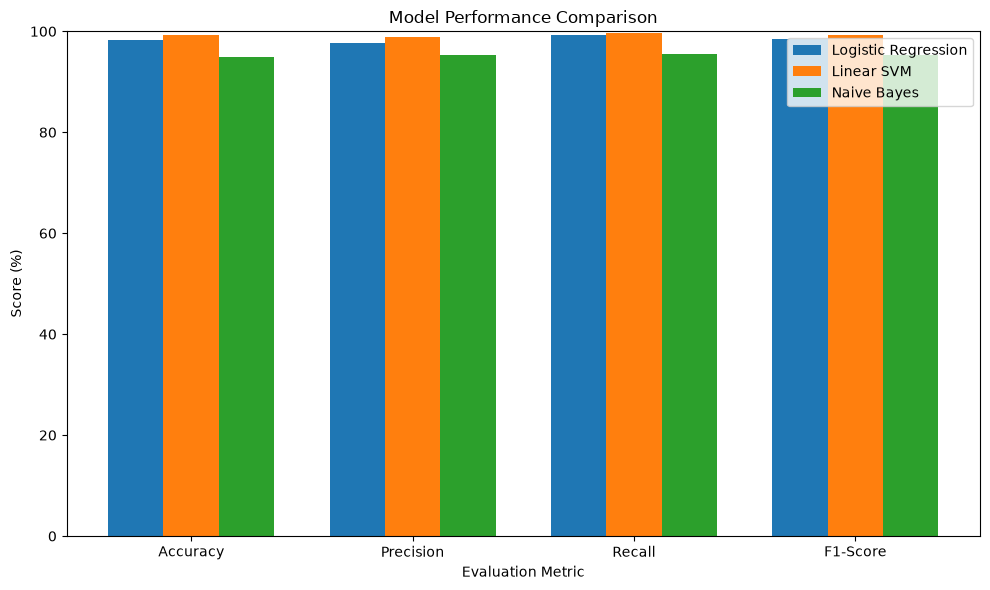

Chart saved to outputs/model_comparison.png


In [155]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

models = model_results["Model"]

x = range(len(metrics))
width = 0.25

plt.figure(figsize=(10, 6))

for i, model in enumerate(models):
    values = model_results.loc[
        i,
        metrics
    ].values

    positions = [
        j + (i - 1) * width
        for j in x
    ]

    plt.bar(
        positions,
        values,
        width=width,
        label=model
    )

plt.xticks(
    list(x),
    metrics
)

plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.title("Model Performance Comparison")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to outputs/model_comparison.png")

Confusion Matrix:
[[3444   46]
 [  14 4224]]


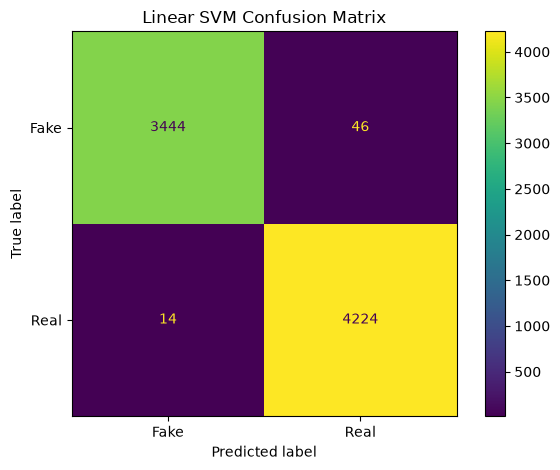

Confusion matrix saved to outputs/confusion_matrix_svm.png


In [156]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate predictions from the leakage-safe Linear SVM
y_unique_pred = svm_model.predict(X_unique_test_tfidf)

# Create confusion matrix
cm = confusion_matrix(
    y_unique_test,
    y_unique_pred
)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

disp.plot()

plt.title("Linear SVM Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../outputs/confusion_matrix_svm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to outputs/confusion_matrix_svm.png")

In [157]:
from sklearn.metrics import classification_report

report = classification_report(
    y_unique_test,
    y_unique_pred,
    target_names=["Fake", "Real"],
    digits=4
)

print(report)

              precision    recall  f1-score   support

        Fake     0.9960    0.9868    0.9914      3490
        Real     0.9892    0.9967    0.9929      4238

    accuracy                         0.9922      7728
   macro avg     0.9926    0.9918    0.9922      7728
weighted avg     0.9923    0.9922    0.9922      7728



In [158]:
error_analysis = ml_df_unique.loc[
    X_unique_test.index[
        y_unique_test != y_unique_pred
    ],
    ["title", "label"]
].copy()

error_analysis["predicted"] = y_unique_pred[
    y_unique_test != y_unique_pred
]

error_analysis["actual_label"] = error_analysis["label"].map({
    0: "Fake",
    1: "Real"
})

error_analysis["predicted_label"] = error_analysis["predicted"].map({
    0: "Fake",
    1: "Real"
})

error_analysis = error_analysis[
    [
        "title",
        "actual_label",
        "predicted_label"
    ]
]

print(
    f"Number of misclassified articles: {len(error_analysis)}"
)

error_analysis.head(20)

Number of misclassified articles: 60


,title,actual_label,predicted_label
27737,Graphic account of Hulk Hogan sex tape read in...,Real,Fake
23959,Sterling quarterback crop lead way into the pl...,Real,Fake
14172,BREAKING NEWS: Obama To Meet With Special Gues...,Fake,Real
25104,Highlights from Reuters' exclusive interview w...,Real,Fake
1679,Court Slams Down Trump’s Order Blocking Fundi...,Fake,Real
10523,AS TRUMP’S POPULARITY SOARS ABROAD…Village In ...,Fake,Real
15872,HOW DOES YOUR STATE’S ECONOMY RANK? Washington...,Fake,Real
16877,SYRIA: Nikki Haley Threatens to “Do More” Desp...,Fake,Real
27261,"U.S. judge approves court, police accord for F...",Real,Fake
13366,ITALIANS FURIOUS! Have You Ever Dreamed Of Liv...,Fake,Real


In [159]:
error_analysis.to_csv(
    "../outputs/error_analysis.csv",
    index=False
)

print("Error analysis saved to outputs/error_analysis.csv")

Error analysis saved to outputs/error_analysis.csv


In [160]:
evaluation_results = model_results.copy()

evaluation_results.to_csv(
    "../outputs/model_evaluation_results.csv",
    index=False
)

print("Evaluation results saved to outputs/model_evaluation_results.csv")

Evaluation results saved to outputs/model_evaluation_results.csv


In [161]:
import sys

sys.path.append("../src")

from database import (
    DATABASE_PATH,
    get_analysis_history
)

print("Database path:")
print(DATABASE_PATH)

print("\nExisting history:")
print(get_analysis_history())

Database path:
C:\D\ExplainableFakeNewsTrustAnalyzer\database\analysis_history.db

Existing history:
[]


In [162]:
from database import get_analysis_history

history = get_analysis_history()

print("Number of saved analyses:", len(history))

for row in history:
    print(row)

Number of saved analyses: 1
(1, '2026-09-04 22:26:38', 'Researchers publish findings from climate study', '', 'Real', 70.14, 'Moderate Trust', 'Moderate Risk')
